# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"



<div style="font-family: Arial, sans-serif; font-size: 14px; line-height: 1.6; text-align: justify;">

<h1 style="font-family: Arial, sans-serif; text-align: center; font-size: 26px;">

<h2 style="font-family: Arial, sans-serif; text-align: center; font-size: 19px;">
🎨 ¿Reconoce realmente el arte o se deja llevar por las apariencias?
</h2>

<p style="text-align: center;">
PROYECTO DE REDES NEURONALES
</p>

<p style="text-align: center;">
Máster Universitario en Inteligencia Artificial
</p>

<p style="text-align: center;">
Asignatura: Redes Neuronales<br>
Grupo 17<br>
Integrantes: Manuela Zambrano Sánchez · Jordi Sala Sanglas · César José Ortiz Sabogal<br>
Fecha: Noviembre de 2026
</p>

</div>

# Actividad: Comparación de estrategias para la clasificación de imágenes

## Enunciado

En esta actividad, el alumno deberá **seleccionar un conjunto de datos de imágenes y desarrollar una solución de clasificación basada en aprendizaje profundo**, utilizando **redes neuronales convolucionales (CNNs)**.

El objetivo principal de la actividad será **evaluar y comparar experimentalmente dos estrategias diferentes** para abordar el problema de clasificación de imágenes:

1. **Entrenamiento de una CNN desde cero (*from scratch*)**.
2. **Utilización de una arquitectura preentrenada mediante *transfer learning* y *fine-tuning*.**

El alumno deberá seleccionar libremente el conjunto de datos sobre el que trabajará. Se podrán utilizar repositorios públicos de datasets, como **Kaggle**.

La solución deberá seguir el **pipeline de trabajo visto en clase**:

1. **Carga del conjunto de datos.**
2. **Inspección y análisis del conjunto de datos.**
3. **Acondicionamiento y preprocesamiento de los datos.**
4. **Diseño de la arquitectura de la red neuronal y entrenamiento del modelo.**
5. **Monitorización del proceso de entrenamiento y toma de decisiones a partir de los resultados obtenidos.**
6. **Evaluación del modelo y análisis de los resultados.**

El trabajo deberá realizarse de forma **experimental**, de manera que las decisiones adoptadas durante el desarrollo de los modelos deberán estar justificadas a partir de los resultados obtenidos en los diferentes experimentos.

---

# Indice de la actividad

1. [Selección y análisis del conjunto de datos](#1)
2. [Estrategia 1: CNN desde cero](#2)
3. [Estrategia 2: redes preentrenadas](#3)
4. [Evaluación y comparación de las estrategias](#4)
5. [Conclusiones](#5)
6. [Referencias](#6)

# Desarrollo de la actividad

<a id="1"></a>
# 1. Selección y análisis del conjunto de datos

### 1.1. Presentación del problema

<p align="justify" style="text-align: justify;">Cuando comenzamos este proyecto, en el grupo valoramos varias ideas sobre qué imágenes utilizar y qué queríamos investigar. Finalmente, elegimos las obras de arte por su variedad de formas, colores y estilos, pero también porque nos surgió una pregunta: ¿hasta qué punto podemos confiar en las clasificaciones que realiza una CNN?</p>

<p align="justify" style="text-align: justify;">Para estudiarlo utilizaremos un conjunto de imágenes de Kaggle, organizado previamente en cinco categorías: dibujos, grabados, iconografía, pinturas y esculturas. Estas categorías nos servirán como referencia para entrenar nuestras redes y evaluar posteriormente sus resultados.</p>

### 1.2. Justificación de nuestra investigación

<p align="justify" style="text-align: justify;">Una CNN puede conseguir un porcentaje elevado de aciertos al clasificar imágenes, pero esto no garantiza que mantenga esos resultados cuando se enfrenta a fotografías diferentes de las utilizadas durante su entrenamiento.</p>

<p align="justify" style="text-align: justify;">Por ejemplo, imaginemos que muchas esculturas aparecen fotografiadas sobre fondos oscuros. La red podría aprender a relacionar ese fondo con la categoría de escultura y equivocarse cuando encuentre una escultura fotografiada sobre un fondo blanco. Es decir, podría estar utilizando detalles de la fotografía en lugar de características propias de la obra.</p>

<p align="justify" style="text-align: justify;">Por eso, queremos comprobar si la CNN es capaz de aplicar lo aprendido a imágenes diferentes de las utilizadas durante su entrenamiento o si sus resultados dependen demasiado de las características de esas fotografías. Esta investigación podría tener una aplicación práctica en los museos, ayudando a clasificar y organizar sus colecciones e incluso a identificar el tipo de obra al que pertenece material que todavía no ha sido catalogado.</p>

### 1.3. Objetivos e hipótesis

<p align="justify" style="text-align: justify;">Nuestro objetivo es construir una CNN desde cero y comparar sus resultados con los de dos modelos previamente entrenados, utilizando técnicas de transfer learning y fine-tuning.</p>

<p align="justify" style="text-align: justify;">Analizaremos la evolución del entrenamiento, los errores de clasificación y qué partes de las imágenes parecen influir en las decisiones de los modelos. También estudiaremos cómo responden ante imágenes de otra colección, siempre que comprobemos que ambos conjuntos son independientes.</p>

<p align="justify" style="text-align: justify;">Partimos de la hipótesis de que los modelos previamente entrenados podrían obtener mejores resultados, aunque su precisión podría disminuir cuando cambien las características de las imágenes.</p>

<p align="justify" style="text-align: justify;">En definitiva, queremos comprobar no solo qué CNN clasifica mejor las obras de arte, sino también si sus resultados siguen siendo fiables cuando se enfrenta a imágenes diferentes.</p>


<h3>1.4. Descarga del conjunto de imágenes</h3>

<p align="justify" style="text-align: justify;">Para desarrollar nuestro proyecto hemos seleccionado el conjunto de datos Art Images (Drawings, Painting, Sculpture, Engraving), disponible en Kaggle. Este conjunto contiene imágenes de obras de arte clasificadas en cinco categorías y nos permitirá entrenar y comparar diferentes redes neuronales convolucionales.
</p>

<p align="justify" style="text-align: justify;">En primer lugar, descargamos las imágenes utilizando la biblioteca kagglehub, que permite acceder directamente al conjunto de datos desde Google Colab. Una vez descargado, analizaremos cómo están organizadas las imágenes y cuántas corresponden a cada categoría.
</p>


In [ ]:
# Librerías necesarias (descomentar si no están instaladas)
# %pip install -q -U kaggle kagglehub

import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
%pip install -q -U kagglehub

import os
from pathlib import Path
import kagglehub

# Descarga del dataset público desde Kaggle (se guarda en caché:
# si se vuelve a ejecutar la celda, no se descarga de nuevo)
download_path = Path(kagglehub.dataset_download(
    "thedownhill/art-images-drawings-painting-sculpture-engraving"))
print("✅ Dataset descargado en:", download_path, "\n")

100%|██████████| 583M/583M [00:09<00:00, 65.4MB/s]

Extracting files...


✅ Dataset descargado en: /root/.cache/kagglehub/datasets/thedownhill/art-images-drawings-painting-sculpture-engraving/versions/2 



#### **- Importando las librerías que vamos a necesitar**

In [ ]:
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Fijamos la semilla para que los resultados se puedan repetir
tf.keras.utils.set_random_seed(42)

### 1.5. Estructura del conjunto de datos

Al descomprimir el dataset aparecen dos carpetas: `dataset` y `musemart`. Las dos tienen la misma organización: `dataset_updated/training_set` y `dataset_updated/validation_set`, con una subcarpeta por cada categoría, con una estructura similar.

Para evitar trabajar con imágenes repetidas, decidimos comprobar si ambas carpetas contenían los mismos archivos. Esta comparación se realiza en el apartado 1.8 mediante el cálculo de huellas digitales MD5.

Los resultados muestran que el 96,8 % de los archivos de `musemart` también están presentes en `dataset`. Por este motivo, utilizaremos únicamente `dataset` para desarrollar nuestro trabajo.

In [ ]:
# Mostramos las carpetas principales y el número de ficheros de cada una
for carpeta in sorted(download_path.glob("*/dataset_updated/*/*")):
    if carpeta.is_dir():
        print(carpeta.relative_to(download_path), "->", len(list(carpeta.iterdir())), "ficheros")

dataset/dataset_updated/training_set/drawings -> 1107 ficheros
dataset/dataset_updated/training_set/engraving -> 760 ficheros
dataset/dataset_updated/training_set/iconography -> 2079 ficheros
dataset/dataset_updated/training_set/painting -> 2128 ficheros
dataset/dataset_updated/training_set/sculpture -> 1745 ficheros
dataset/dataset_updated/validation_set/drawings -> 122 ficheros
dataset/dataset_updated/validation_set/engraving -> 84 ficheros
dataset/dataset_updated/validation_set/iconography -> 231 ficheros
dataset/dataset_updated/validation_set/painting -> 236 ficheros
dataset/dataset_updated/validation_set/sculpture -> 193 ficheros
musemart/dataset_updated/training_set/drawings -> 162 ficheros
musemart/dataset_updated/training_set/engraving -> 248 ficheros
musemart/dataset_updated/training_set/iconography -> 681 ficheros
musemart/dataset_updated/training_set/painting -> 2264 ficheros
musemart/dataset_updated/training_set/sculpture -> 473 ficheros
musemart/dataset_updated/validation_

### 1.6. Registro de las imágenes


In [ ]:
DATA_DIR = download_path / "dataset" / "dataset_updated"
clases = sorted(p.name for p in (DATA_DIR / "training_set").iterdir() if p.is_dir())
print("Clases:", clases)
print("Número de clases:", len(clases))

def huella(ruta):
    # Código único de cada fichero: dos ficheros idénticos tienen la misma huella
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

filas = []
for carpeta in ["training_set", "validation_set"]:
    for clase in clases:
        for ruta in (DATA_DIR / carpeta / clase).iterdir():
            try:
                with Image.open(ruta) as img:
                    img.load()
                    filas.append([str(ruta), carpeta, clase, img.width, img.height, img.mode, huella(ruta), True])
            except Exception:
                filas.append([str(ruta), carpeta, clase, None, None, None, None, False])

df = pd.DataFrame(filas, columns=["ruta", "carpeta", "clase", "ancho", "alto", "modo", "huella", "valida"])
print("\nFicheros totales:", len(df))
print("Imágenes válidas:", df["valida"].sum())
print("Imágenes corruptas:", (~df["valida"]).sum())

Clases: ['drawings', 'engraving', 'iconography', 'painting', 'sculpture']
Número de clases: 5

Ficheros totales: 8685
Imágenes válidas: 8577
Imágenes corruptas: 108



#### Interpretación de los resultados

El conjunto de datos contiene 8.685 archivos distribuidos en cinco categorías: *drawings*, *engraving*, *iconography*, *painting* y *sculpture*.

De estos archivos, 8.577 se han podido abrir correctamente, mientras que 108 han presentado errores de lectura, lo que representa aproximadamente el 1,24 % del total.

Consideramos importante realizar esta comprobación antes del entrenamiento, ya que los archivos que no pueden procesarse podrían provocar errores durante la carga de las imágenes.En los siguientes apartados analizaremos la distribución de las categorías y la existencia de imágenes duplicadas para preparar adecuadamente los datos antes de entrenar nuestra CNN.

### 1.7. Distribución de las clases

<p align="justify" style="text-align: justify;">Una vez identificadas las imágenes válidas en el apartado anterior, vamos a analizar cómo se distribuyen entre las cinco categorías de nuestro conjunto de datos. Consideramos importante realizar esta comprobación antes de entrenar nuestra red neuronal convolucional (CNN), ya que necesitamos conocer si disponemos de un número similar de imágenes para cada clase.</p>

<p align="justify" style="text-align: justify;">Para ello, partimos del DataFrame <code>df</code>, que hemos creado en el apartado 1.6. En esta tabla hemos registrado la información de cada archivo, incluyendo su ruta, carpeta de origen, categoría, dimensiones, modo de color, huella digital y si se ha podido abrir correctamente.</p>

<p align="justify" style="text-align: justify;">En primer lugar, mediante la instrucción <code>validas = df[df["valida"]]</code>, seleccionamos únicamente las imágenes que se han podido abrir correctamente, obteniendo un total de 8.577 imágenes válidas.</p>

<p align="justify" style="text-align: justify;">A continuación, utilizamos la función <code>pd.crosstab()</code> de la biblioteca pandas para contar cuántas imágenes corresponden a cada categoría, diferenciando entre las carpetas originales <code>training_set</code> y <code>validation_set</code>. También incorporamos los totales para facilitar la comparación.</p>

<p align="justify" style="text-align: justify;">Finalmente, representamos el número de imágenes de cada clase mediante un gráfico de barras. Para ello, utilizamos la función <code>value_counts()</code>, que cuenta las imágenes de cada categoría, y Matplotlib para representar los resultados. Esta gráfica nos permite observar las diferencias entre las cinco clases.</p>


| Categoría | Entrenamiento | Validación | Total | Porcentaje |
|---|---:|---:|---:|---:|
| Drawings | 1.107 | 122 | 1.229 | 14,33 % |
| Engraving | 757 | 84 | 841 | 9,81 % |
| Iconography | 2.077 | 231 | 2.308 | 26,91 % |
| Painting | 2.042 | 228 | 2.270 | 26,47 % |
| Sculpture | 1.738 | 191 | 1.929 | 22,49 % |
| Total | 7.721 | 856 | 8.577 | 100 % |

<p align="justify" style="text-align: justify;">Al analizar la tabla y el gráfico de barras, observamos que las categorías no tienen el mismo número de imágenes. La más representada es iconography, con 2.308 imágenes (26,91 %), seguida de painting, con 2.270 (26,47 %), y sculpture, con 1.929 (22,49 %).</p>

<p align="justify" style="text-align: justify;">Por el contrario, drawings cuenta con 1.229 imágenes (14,33 %), mientras que engraving es la categoría menos representada, con 841 imágenes (9,81 %).</p>

<p align="justify" style="text-align: justify;">Si comparamos las categorías con mayor y menor número de imágenes, comprobamos que tenemos aproximadamente 2,74 veces más imágenes de iconography que de engraving. Por tanto, nuestro conjunto de datos presenta un desequilibrio entre las clases.</p>



carpeta      training_set  validation_set  Total
clase                                           
drawings             1107             122   1229
engraving             757              84    841
iconography          2077             231   2308
painting             2042             228   2270
sculpture            1738             191   1929
Total                7721             856   8577


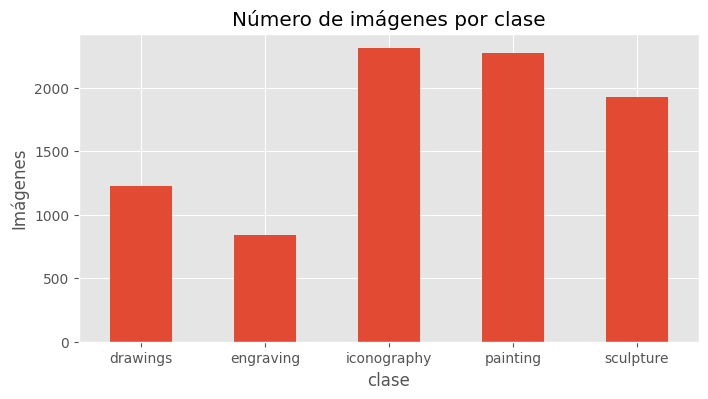

In [ ]:
validas = df[df["valida"]]
tabla = pd.crosstab(validas["clase"], validas["carpeta"], margins=True, margins_name="Total")
print(tabla)

# Gráfico de barras con el número de imágenes por clase
plt.style.use("ggplot")
validas["clase"].value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.title("Número de imágenes por clase")
plt.ylabel("Imágenes")
plt.xticks(rotation=0)
plt.show()

#### Interpretación de los resultados

<p align="justify" style="text-align: justify;">Este desequilibrio puede influir en el entrenamiento de nuestra CNN, ya que la red dispone de más ejemplos de algunas categorías que de otras. Esto podría favorecer el aprendizaje de las clases más representadas y dificultar el reconocimiento de aquellas que tienen menos imágenes.</p>

<p align="justify" style="text-align: justify;">Por este motivo, cuando evaluemos el comportamiento de nuestra red neuronal, no nos fijaremos únicamente en la exactitud global (accuracy), sino que analizaremos también la precisión (precision), la sensibilidad (recall) y el F1-score de cada categoría. De esta forma podremos comprobar si el modelo clasifica correctamente las cinco clases o si presenta mayores dificultades con alguna de ellas.</p>

<p align="justify" style="text-align: justify;">También debemos tener en cuenta que las cantidades obtenidas corresponden a las imágenes válidas, pero todavía incluyen posibles duplicados. Por tanto, la distribución definitiva de las clases podría cambiar después del proceso de limpieza que realizaremos en el siguiente apartado.</p>



<h3>1.8. Comprobación de imágenes repetidas</h3>

<p align="justify" style="text-align: justify;">En este apartado vamos a comprobar lo que adelantamos en el punto 1.5 sobre la similitud entre las carpetas <code>dataset</code> y <code>musemart</code>. Para ello, utilizamos las huellas digitales MD5 que calculamos anteriormente y comparamos los archivos de ambas carpetas.
</p>

<p align="justify" style="text-align: justify;">Mediante la instrucción <code>huellas_dataset = set(validas["huella"])</code>, obtenemos las huellas de las imágenes válidas de <code>dataset</code>. Después, con la función <code>huella(r)</code>, calculamos las correspondientes a los archivos de <code>musemart</code> y contamos cuántas coinciden.
</p>

<p align="justify" style="text-align: justify;">Los resultados muestran que 3.966 de los 4.099 archivos de <code>musemart</code> ya se encuentran en <code>dataset</code>, lo que supone un 96,76 %. De esta forma verificamos lo indicado en el apartado 1.5 y justificamos que trabajemos únicamente con <code>dataset</code>.
</p>

<p align="justify" style="text-align: justify;">Por otra parte, mediante <code>validas.duplicated("huella", keep="first")</code>, comprobamos si existen archivos repetidos dentro de <code>dataset</code>. Encontramos 1.492 duplicados entre las 8.577 imágenes válidas, por lo que disponemos de 7.085 archivos con huellas diferentes. Estos duplicados se eliminarán en el apartado 1.11, antes de dividir las imágenes en entrenamiento, validación y prueba.
</p>


<p align="justify" style="text-align: justify;">No obstante, debemos tener en cuenta que MD5 permite identificar archivos idénticos, pero no necesariamente imágenes visualmente iguales guardadas con distinta resolución, formato o compresión. Para un análisis más exhaustivo podrían utilizarse técnicas de comparación perceptual, como pHash, que permiten identificar imágenes visualmente similares. En nuestro caso, hemos optado por eliminar los duplicados exactos en el apartado 1.11, manteniendo un procedimiento de limpieza sencillo y reproducible.
</p>




In [ ]:
repetidas = validas[validas.duplicated("huella", keep="first")]
print("Imágenes repetidas dentro de 'dataset':", len(repetidas))

# ¿Cuántas imágenes de musemart ya están en dataset?
musemart = download_path / "musemart" / "dataset_updated"
if musemart.exists():
    huellas_dataset = set(validas["huella"])
    rutas_musemart = [r for r in musemart.rglob("*") if r.is_file()]
    iguales = sum(huella(r) in huellas_dataset for r in rutas_musemart)
    print(f"Imágenes de musemart que ya están en dataset: {iguales} de {len(rutas_musemart)}")

Imágenes repetidas dentro de 'dataset': 1492
Imágenes de musemart que ya están en dataset: 3966 de 4099




<h3>1.9. Dimensiones de las imágenes</h3>

<p align="justify" style="text-align: justify;">Una vez analizada la distribución de las clases y comprobada la existencia de imágenes duplicadas, estudiaremos las dimensiones y los modos de color de las 8.577 imágenes válidas. Este análisis nos permitirá conocer las diferencias entre los archivos originales y determinar qué transformaciones necesitaremos antes de introducirlos en nuestra red neuronal convolucional (CNN).
</p>

<p align="justify" style="text-align: justify;">Para ello, utilizamos la función <code>describe()</code> de pandas, que nos proporciona estadísticas sobre el ancho y el alto de las imágenes, como la media, la mediana, los valores mínimos y máximos y los cuartiles. También empleamos <code>value_counts()</code> para identificar los modos de color y representamos mediante dos histogramas la distribución de los tamaños.
</p>


             ancho         alto
count  8577.000000  8577.000000
mean    355.088842   369.410983
std     150.923078   145.186099
min      37.000000    92.000000
25%     267.000000   320.000000
50%     290.000000   320.000000
75%     427.000000   370.000000
max    2016.000000  1512.000000

Modos de color:
modo
RGB     8525
L         36
RGBA      11
P          4
CMYK       1
Name: count, dtype: int64


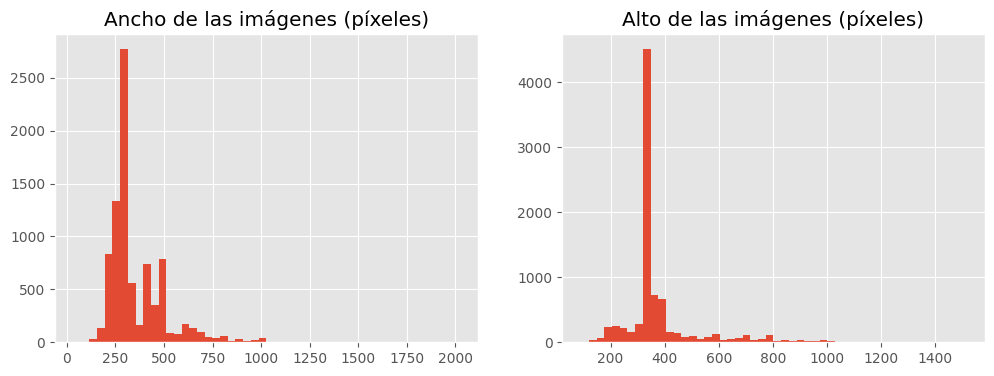

In [ ]:
print(validas[["ancho", "alto"]].describe())
print("\nModos de color:")
print(validas["modo"].value_counts())

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(validas["ancho"], bins=50)
plt.title("Ancho de las imágenes (píxeles)")
plt.subplot(1, 2, 2)
plt.hist(validas["alto"], bins=50)
plt.title("Alto de las imágenes (píxeles)")
plt.show()

#### Interpretación de los resultados
<p align="justify" style="text-align: justify;">Al observar los resultados y los histogramas, comprobamos que las imágenes presentan dimensiones diferentes. El ancho medio es de 355 píxeles y el alto medio de 369, mientras que las medianas son de 290 y 320 píxeles, respectivamente. También encontramos imágenes muy pequeñas y otras considerablemente mayores, lo que confirma que no todas tienen el mismo tamaño.
</p>

<p align="justify" style="text-align: justify;">En cuanto al color, observamos que la gran mayoría de las imágenes están en formato RGB (8.525 de las 8.577 válidas), aunque también existen algunas en escala de grises y otros modos de color. Por tanto, necesitaremos unificar tanto las dimensiones como los canales de color.
</p>

<p align="justify" style="text-align: justify;">En consecuencia, en el apartado 1.11 debido a estos resultados, hemos decidido unificar las imágenes a un tamaño de 160 × 160 píxeles y tres canales de color RGB. Esta elección responde a la necesidad de utilizar unas dimensiones de entrada comunes para nuestra CNN y las dos arquitecturas preentrenadas que aplicaremos posteriormente, MobileNetV2 y ResNet50. De esta forma, podremos comparar los resultados de los tres modelos trabajando con imágenes de las mismas dimensiones, manteniendo además un tamaño moderado que facilite el entrenamiento.
</p>




<h3>1.10. Visualización de imágenes por categoría</h3>

<p align="justify" style="text-align: justify;">A continuación, mostramos algunos ejemplos de las cinco categorías de nuestro conjunto de datos para observar sus características visuales y las posibles similitudes entre ellas. Esta visualización nos ayudará a comprender mejor las imágenes que posteriormente tendrá que clasificar nuestra CNN.
</p>



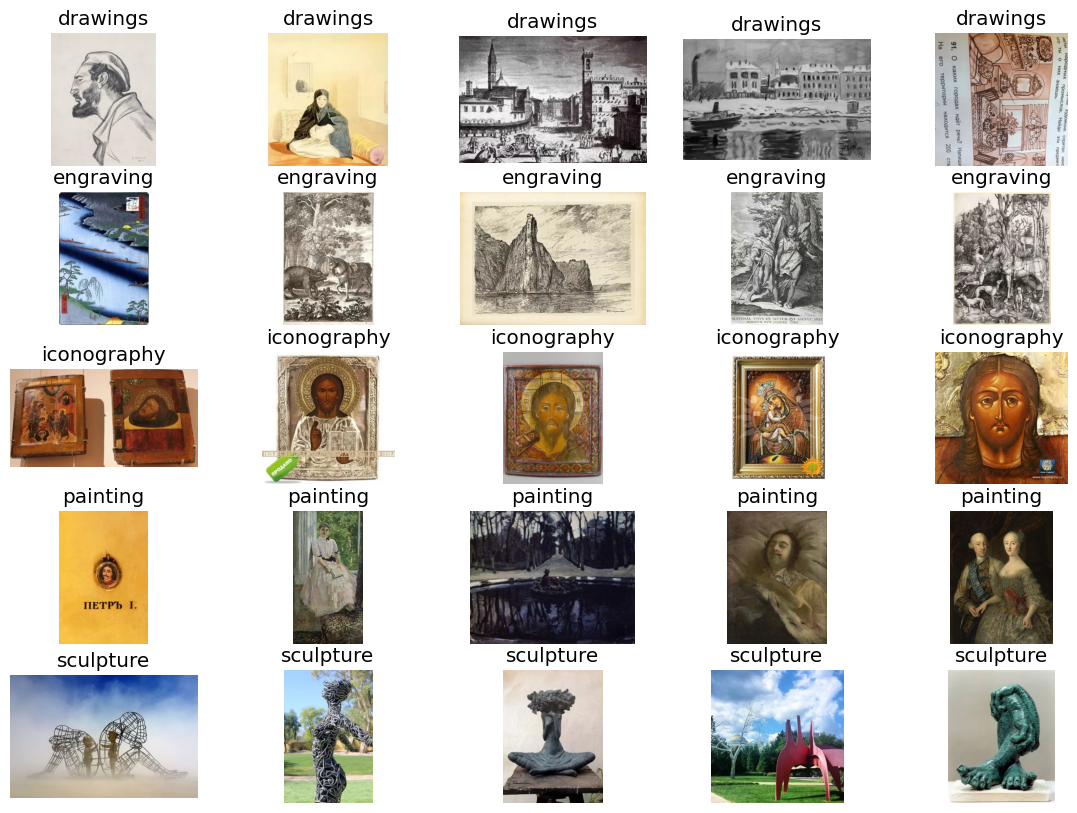

In [ ]:
fig = plt.figure(figsize=(14, 10))
n = 1
for clase in clases:
    ejemplos = validas[validas["clase"] == clase].sample(5, random_state=42)
    for ruta in ejemplos["ruta"]:
        fig.add_subplot(len(clases), 5, n)
        plt.imshow(Image.open(ruta).convert("RGB"))
        plt.title(clase)
        plt.axis("off")
        n += 1
plt.show()


<h3>1.11. Preparación de las imágenes y división de los datos</h3>

<p align="justify" style="text-align: justify;">Una vez analizadas las características de nuestro conjunto de datos, vamos a preparar las imágenes para utilizarlas en el entrenamiento de las redes neuronales. Para ello, seguiremos cinco pasos:
</p>

<ol>
<li>Eliminar los archivos duplicados.</li>
<li>Convertir las imágenes a RGB y ajustar su tamaño a 160 × 160 píxeles.</li>
<li>Transformar las cinco categorías en etiquetas numéricas.</li>
<li>Dividir las imágenes en entrenamiento, validación y prueba.</li>
<li>Normalizar los valores de los píxeles.</li>
</ol>

<p align="justify" style="text-align: justify;">En primer lugar, partimos de las 8.577 imágenes válidas que identificamos anteriormente y utilizamos <code>drop_duplicates("huella")</code> para eliminar los 1.492 archivos repetidos mediante MD5. De esta forma, nos quedamos con 7.085 imágenes con huellas diferentes y evitamos que un mismo archivo se utilice más de una vez en el experimento.
</p>

<p align="justify" style="text-align: justify;">A continuación, abrimos las imágenes con PIL, las convertimos a RGB y las redimensionamos a 160 × 160 píxeles, siguiendo el criterio que justificamos en el apartado 1.9. Con ello conseguimos que todas tengan las mismas dimensiones y tres canales de color, tanto para nuestra CNN como para MobileNetV2 y ResNet50.
</p>

<p align="justify" style="text-align: justify;">Después, transformamos las cinco categorías artísticas en etiquetas numéricas del 0 al 4. Para ello, utilizamos <code>clases.index(c)</code>, que asigna a cada imagen el número correspondiente a su categoría. Así obtenemos dos conjuntos de datos: <code>X</code>, que contiene las imágenes, e <code>y</code>, que contiene sus etiquetas.
</p>

<p align="justify" style="text-align: justify;">El siguiente paso consiste en dividir los datos mediante <code>train_test_split()</code>. Primero reservamos el 20 % para la prueba final y, del 80 % restante, separamos otro 20 % para validación. Por tanto, la distribución definitiva es del 64 % para entrenamiento, 16 % para validación y 20 % para prueba. Utilizamos <code>stratify</code> para mantener aproximadamente la misma proporción de las cinco categorías en cada conjunto y <code>random_state=42</code> para poder reproducir la división.
</p>

<p align="justify" style="text-align: justify;">Esta separación es importante porque cada conjunto cumple una función diferente. Con las imágenes de entrenamiento la red aprende a reconocer las características de las obras; con las de validación comprobamos su comportamiento y seleccionamos los modelos; y reservamos las de prueba para evaluar el resultado final con imágenes que no se hayan utilizado en las etapas anteriores.
</p>

<p align="justify" style="text-align: justify;">Por último, convertimos los valores de los píxeles a <code>float32</code> y los dividimos entre 255 para que queden comprendidos entre 0 y 1. Esta normalización facilita el entrenamiento de nuestra CNN. Más adelante, al utilizar MobileNetV2 y ResNet50, aplicaremos dentro de cada modelo las transformaciones adicionales que necesitan sus pesos preentrenados.
</p>


In [ ]:
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # oculta el aviso de imágenes con paleta

TAMANO = 160
# 160x160: buen equilibrio entre detalle y tiempo de entrenamiento,
# y es un tamaño nativo de MobileNetV2 (mismo tamaño en las dos estrategias)

# 1. Imágenes válidas y sin repetir
limpias = validas.drop_duplicates("huella").reset_index(drop=True)
print("Imágenes que vamos a usar:", len(limpias))

# 2 y 3. Cargamos las imágenes y sus etiquetas
print("[INFO]: Cargando imágenes...")
X = np.array([np.array(Image.open(r).convert("RGB").resize((TAMANO, TAMANO))) for r in limpias["ruta"]])
y = np.array([clases.index(c) for c in limpias["clase"]])
print("X:", X.shape, " y:", y.shape)

# 4. Tres subconjuntos
# Paso 1: 80 % entrenamiento y 20 % test
x_train, x_te, y_train, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
# Paso 2: del entrenamiento separamos un 20 % para validación
# Resultado final: 64 % train, 16 % validación y 20 % test
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.20, stratify=y_train, random_state=42)

# 5. Normalizamos al rango 0-1
x_tr = x_tr.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_te = x_te.astype("float32") / 255.0

print("Train:", x_tr.shape, " Validación:", x_val.shape, " Test:", x_te.shape)
print(pd.DataFrame({"train": np.bincount(y_tr), "validación": np.bincount(y_val),
                    "test": np.bincount(y_te)}, index=clases))

Imágenes que vamos a usar: 7085
[INFO]: Cargando imágenes...
X: (7085, 160, 160, 3)  y: (7085,)
Train: (4534, 160, 160, 3)  Validación: (1134, 160, 160, 3)  Test: (1417, 160, 160, 3)
             train  validación  test
drawings       786         197   246
engraving      537         134   168
iconography   1474         368   460
painting       526         132   164
sculpture     1211         303   379


**Nota:** las etiquetas son números enteros (0, 1, 2, 3, 4), así que usaremos la función de pérdida `sparse_categorical_crossentropy`. Si usáramos *one-hot encoding* (`to_categorical`), tendríamos que usar `categorical_crossentropy`.

### 1.12. Resumen del conjunto de datos


<p align="justify" style="text-align: justify;">A continuación, presentamos una tabla resumen con las principales características del conjunto de datos, una vez realizado el análisis de las imágenes, eliminados los archivos duplicados y preparados los conjuntos de entrenamiento, validación y prueba.
</p>


| Característica | Valor |
|---|---|
| Tipo de problema | Clasificación de imágenes en 5 clases |
| Clases | drawings, engraving, iconography, painting, sculpture |
| Imágenes en `dataset` | 8.685 |
| Imágenes corruptas | 108 |
| Imágenes repetidas | 1.492 |
| Imágenes utilizadas | 7.085 |
| Tamaño usado | 160 × 160 × 3 |
| Train / Validación / Test | 4.534 / 1.134 / 1.417 (64 % / 16 % / 20 %) |


<a id="2"></a>
# 2. Estrategia 1: CNN desde cero (*from scratch*)


<p align="justify" style="text-align: justify;">En esta primera estrategia vamos a construir nuestra propia red neuronal convolucional (CNN), sin utilizar modelos previamente entrenados. Nuestro objetivo es comprobar cómo aprende a clasificar las cinco categorías artísticas y qué dificultades aparecen durante el entrenamiento.
</p>

<p align="justify" style="text-align: justify;">Para ello, comenzaremos con una arquitectura sencilla que utilizaremos como referencia y realizaremos seis experimentos, incorporando progresivamente distintas técnicas para intentar mejorar sus resultados y reducir el sobreajuste. De esta forma, podremos analizar cómo influye cada modificación en el comportamiento de nuestra CNN.
</p>

<p align="justify" style="text-align: justify;">En todos los experimentos utilizaremos el optimizador Adam y un tamaño de lote (batch size) de 32 imágenes. Inicialmente estableceremos un máximo de 30 épocas y, a partir del cuarto experimento, lo ampliaremos a 50. También utilizaremos EarlyStopping, que detendrá el entrenamiento cuando la pérdida de validación no mejore durante cinco épocas consecutivas y recuperará los pesos correspondientes a la mejor época.
</p>





| Experimento | Qué cambiamos |
|---|---|
| E1 | Red base |
| E2 | Añadimos *Dropout* |
| E3 | Cambiamos `Flatten` por `GlobalAveragePooling2D` (menos parámetros) |
| E4 | Añadimos *Batch Normalization* |
| E5 | Añadimos regularización L2 |
| E6 | Añadimos *Data Augmentation* |






<h3>Funciones para mostrar los resultados</h3>

<p align="justify" style="text-align: justify;">Antes de comenzar los experimentos, definimos dos funciones auxiliares que utilizaremos en los distintos entrenamientos:
</p>

<ul>
<li><b>parada():</b> configura EarlyStopping para detener el entrenamiento cuando la pérdida de validación (val_loss) no mejore durante cinco épocas consecutivas. Además, recupera los pesos correspondientes a la época con menor pérdida de validación, evitando continuar entrenando innecesariamente.</li>

<li><b>mostrar_resultados(H, nombre):</b> representa dos gráficas para cada experimento: la evolución de la pérdida (loss) y la exactitud (accuracy), tanto en entrenamiento como en validación. También identifica la época con menor pérdida de validación y guarda sus métricas en una tabla para comparar posteriormente los modelos.</li>
</ul>

<p align="justify" style="text-align: justify;">Por último, utilizamos la lista <code>resultados</code> para almacenar las métricas de los seis experimentos. De esta forma, podremos comparar sus resultados sin repetir el mismo código.
</p>



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

resultados = []      # tabla con los resultados de todos los experimentos

def parada():
    # Creamos un EarlyStopping nuevo en cada entrenamiento, para que no recuerde
    # la mejor val_loss del experimento anterior
    return EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)

def mostrar_resultados(H, nombre):
    epocas = len(H.history["loss"])
    mejor = np.argmin(H.history["val_loss"])      # mejor época (la de menor val_loss)
    x = np.arange(0, epocas)

    plt.style.use("ggplot")
    plt.figure(figsize=(13, 4))

    # Gráfica 1: pérdida (loss)
    plt.subplot(1, 2, 1)
    plt.plot(x, H.history["loss"], label="train_loss")
    plt.plot(x, H.history["val_loss"], label="val_loss")
    plt.axvline(mejor, color="gray", linestyle="--", label=f"mejor época ({mejor + 1})")
    plt.title("Training Loss - " + nombre)
    plt.xlabel("Epoch #")
    plt.ylabel("Loss")
    plt.legend()

    # Gráfica 2: accuracy
    plt.subplot(1, 2, 2)
    plt.plot(x, H.history["accuracy"], label="train_acc")
    plt.plot(x, H.history["val_accuracy"], label="val_acc")
    plt.axvline(mejor, color="gray", linestyle="--", label=f"mejor época ({mejor + 1})")
    plt.title("Training Accuracy - " + nombre)
    plt.xlabel("Epoch #")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Guardamos los valores de la mejor época
    resultados.append({"experimento": nombre,
                       "épocas": epocas,
                       "train_acc": round(H.history["accuracy"][mejor], 4),
                       "val_acc": round(H.history["val_accuracy"][mejor], 4),
                       "val_loss": round(H.history["val_loss"][mejor], 4)})
    print(pd.DataFrame(resultados))


<h3>2.1. Experimento E1: red base</h3>

<p align="justify" style="text-align: justify;">En nuestro primer experimento construimos una red neuronal convolucional (CNN) desde cero, que utilizaremos como modelo de referencia para los siguientes experimentos. Hemos elegido una arquitectura formada por tres bloques convolucionales porque nos permite aprender progresivamente las características visuales de las obras de arte, sin comenzar con una red demasiado compleja.
</p>

<p align="justify" style="text-align: justify;">Cada bloque contiene una capa Conv2D con filtros de 3 × 3 píxeles y función de activación ReLU, seguida de una capa MaxPooling2D de 2 × 2. Utilizamos 32, 64 y 128 filtros, respectivamente, aumentando su número para que la red pueda identificar características cada vez más variadas. Las primeras capas pueden aprender bordes y contrastes, mientras que las siguientes combinan esta información para reconocer formas y texturas más complejas. Al mismo tiempo, MaxPooling reduce las dimensiones espaciales de los mapas de características, conservando las respuestas más destacadas.
</p>

<p align="justify" style="text-align: justify;">La parte final de nuestra CNN, denominada <i>Top Model</i>, está formada por las capas encargadas de utilizar las características extraídas por los bloques convolucionales para realizar la clasificación de las imágenes.
</p>


<p align="justify" style="text-align: justify;">A continuación, mostramos en la Figura 1 la arquitectura elegida y cómo cambian las dimensiones de los datos al atravesar las distintas capas.
</p>


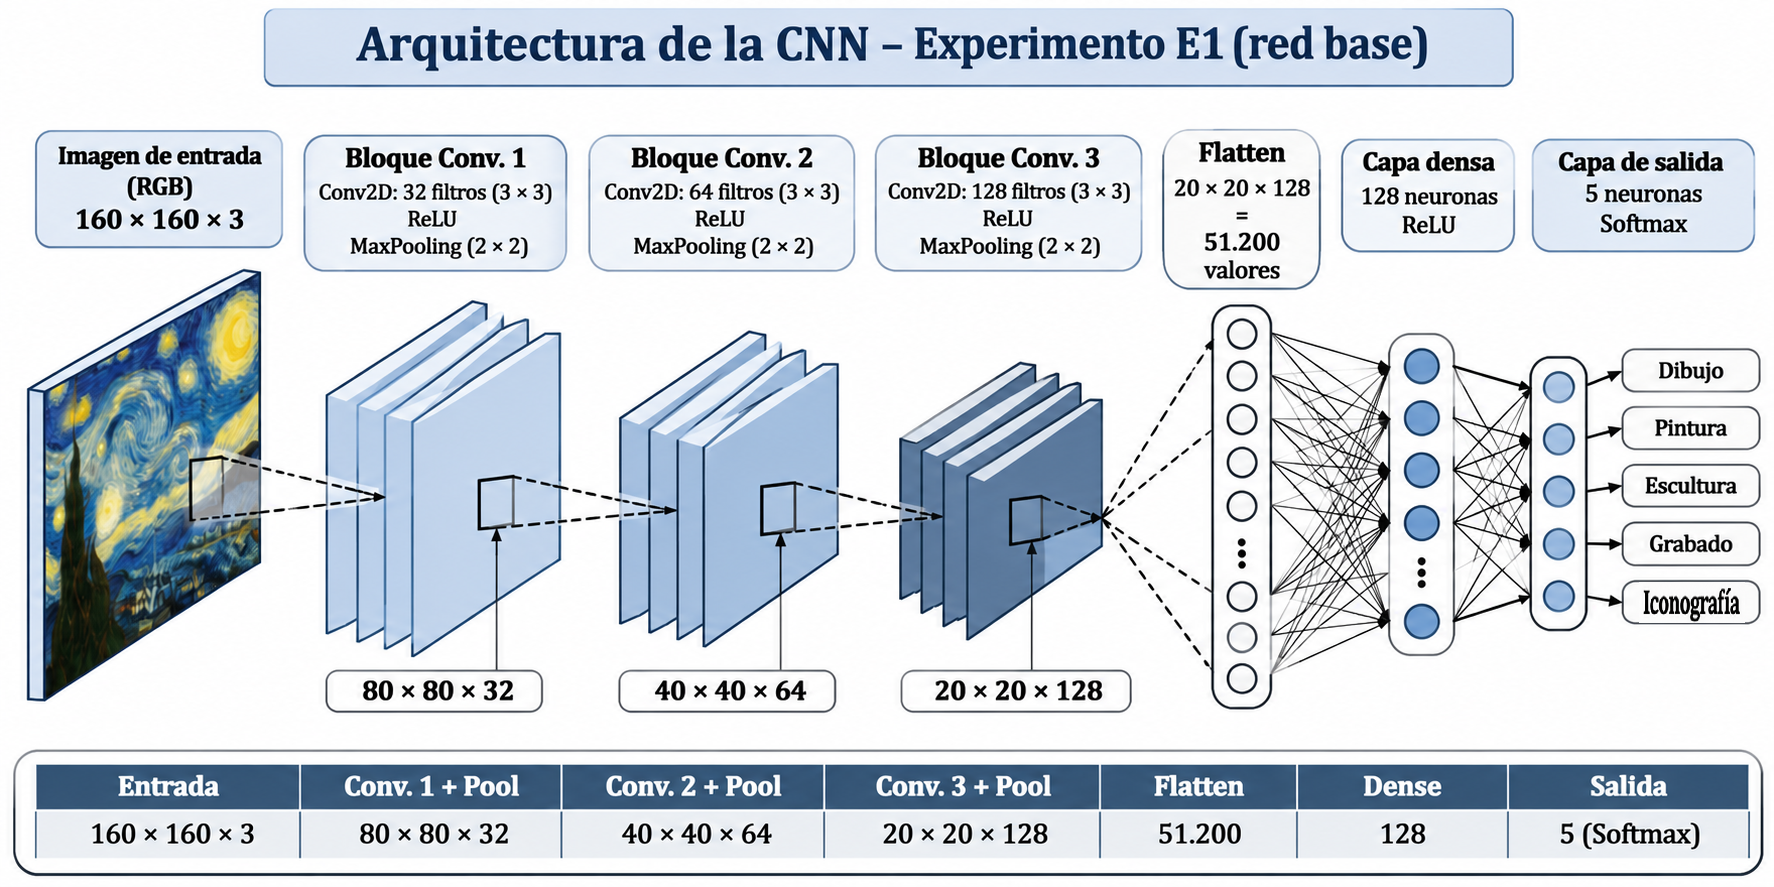

In [ ]:
tf.keras.utils.set_random_seed(42)   # misma semilla en cada experimento: resultados repetibles
model_1 = Sequential()
model_1.add(layers.Input(shape=(TAMANO, TAMANO, 3)))
# BASE MODEL
model_1.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu"))
model_1.add(layers.MaxPooling2D((2, 2)))
model_1.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu"))
model_1.add(layers.MaxPooling2D((2, 2)))
model_1.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu"))
model_1.add(layers.MaxPooling2D((2, 2)))
# TOP MODEL
model_1.add(layers.Flatten())
model_1.add(layers.Dense(128, activation="relu"))
model_1.add(layers.Dense(len(clases), activation="softmax"))
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

[INFO]: Entrenando red neuronal...
Epoch 1/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 28s 123ms/step - accuracy: 0.6330 - loss: 0.9734 - val_accuracy: 0.7143 - val_loss: 0.7631
Epoch 2/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.7486 - loss: 0.6727 - val_accuracy: 0.7522 - val_loss: 0.7120
Epoch 3/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8033 - loss: 0.5270 - val_accuracy: 0.7875 - val_loss: 0.6739
Epoch 4/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.8555 - loss: 0.3810 - val_accuracy: 0.7646 - val_loss: 0.7844
Epoch 5/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.8862 - loss: 0.3086 - val_accuracy: 0.7769 - val_loss: 0.7879
Epoch 6/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9160 - loss: 0.2530 - val_accuracy: 0.7813 - val_loss: 0.9507
Epoch 7/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9435 - loss: 0.1544 - val_accuracy: 0.7407 - val_loss: 1.2721
Epoch 8/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accur

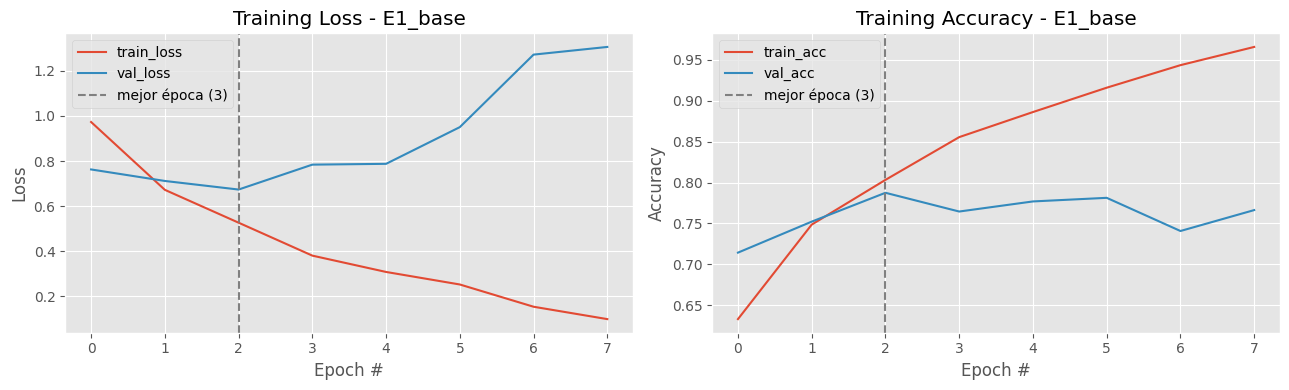

  experimento  épocas  train_acc  val_acc  val_loss
0     E1_base       8     0.8033   0.7875    0.6739


In [ ]:
model_1.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

print("[INFO]: Entrenando red neuronal...")
H = model_1.fit(x_tr, y_tr, validation_data=(x_val, y_val),
          batch_size=32, epochs=30, callbacks=[parada()])
mostrar_resultados(H, "E1_base")


<p align="justify" style="text-align: justify;"><b>Análisis:</b> La red base alcanza su mejor resultado en la <b>época 3</b>, señalada mediante la línea discontinua, con un <i>accuracy</i> de validación de <b>0,79</b> y una pérdida de validación de <b>0,67</b>. En ese momento, los valores de <i>accuracy</i> de entrenamiento (0,80) y validación (0,79) son muy similares, lo que indica que el modelo todavía presenta una buena capacidad de generalización.
</p>

<p align="justify" style="text-align: justify;">Sin embargo, a partir de esa época observamos un <b>sobreajuste evidente</b>, que podemos identificar en las dos gráficas:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b>Pérdida:</b> la pérdida de entrenamiento continúa disminuyendo hasta 0,10, mientras que la de validación aumenta hasta 1,31, casi el doble de su mejor valor.</li>
<li align="justify"><b>Accuracy:</b> el de entrenamiento aumenta progresivamente hasta 0,97, mientras que el de validación se estanca e incluso desciende hasta 0,74 en la época 7, terminando en 0,77.</li>
</ul>

<p align="justify" style="text-align: justify;">La separación progresiva entre las curvas indica que la red aprende cada vez mejor las imágenes de entrenamiento, pero no consigue mejorar de la misma manera con imágenes que no ha visto anteriormente. Es decir, el modelo presenta dificultades para generalizar. El mecanismo <i>Early Stopping</i> detiene el entrenamiento en la época 8 y recupera los pesos de la época 3, correspondiente a la menor pérdida de validación.
</p>

<p align="justify" style="text-align: justify;">Una posible causa de este comportamiento es el elevado número de parámetros de la arquitectura. La capa <code>Flatten</code> transforma los mapas de características en un vector de 51.200 valores (20 × 20 × 128). Al conectarlo con la capa densa de 128 neuronas, se generan aproximadamente <b>6,55 millones de pesos</b>, una cantidad considerable teniendo en cuenta que disponemos de 4.534 imágenes de entrenamiento. Esta complejidad puede favorecer el sobreajuste.
</p>

<p align="justify" style="text-align: justify;"><b>Decisión para E2:</b> En el siguiente experimento incorporamos <i>Dropout</i>, una técnica de regularización que desactiva aleatoriamente una parte de las neuronas durante el entrenamiento. Con ello buscamos reducir la dependencia de conexiones concretas, limitar el sobreajuste y comprobar si conseguimos mejorar la capacidad de generalización de nuestra CNN.
</p>


### 2.2. Experimento E2: *Dropout*

**Problema:** sobreajuste en E1. El *Dropout* apaga al azar el 50 % de las neuronas en cada paso del entrenamiento, así la red no puede depender de unas pocas neuronas y generaliza mejor.

In [ ]:
tf.keras.utils.set_random_seed(42)   # misma semilla en cada experimento: resultados repetibles
model_2 = Sequential()
model_2.add(layers.Input(shape=(TAMANO, TAMANO, 3)))
model_2.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu"))
model_2.add(layers.MaxPooling2D((2, 2)))
model_2.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu"))
model_2.add(layers.MaxPooling2D((2, 2)))
model_2.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu"))
model_2.add(layers.MaxPooling2D((2, 2)))
model_2.add(layers.Flatten())
model_2.add(layers.Dropout(0.5))                       # NUEVO
model_2.add(layers.Dense(128, activation="relu"))
model_2.add(layers.Dropout(0.5))                       # NUEVO
model_2.add(layers.Dense(len(clases), activation="softmax"))

[INFO]: Entrenando red neuronal...
Epoch 1/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 14s 66ms/step - accuracy: 0.5794 - loss: 1.0773 - val_accuracy: 0.6526 - val_loss: 0.8868
Epoch 2/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.6970 - loss: 0.8207 - val_accuracy: 0.7601 - val_loss: 0.6584
Epoch 3/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.7563 - loss: 0.6751 - val_accuracy: 0.7787 - val_loss: 0.6278
Epoch 4/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.7885 - loss: 0.5800 - val_accuracy: 0.8034 - val_loss: 0.6060
Epoch 5/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.8059 - loss: 0.5193 - val_accuracy: 0.7998 - val_loss: 0.5654
Epoch 6/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.8174 - loss: 0.4761 - val_accuracy: 0.7840 - val_loss: 0.6294
Epoch 7/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.8573 - loss: 0.3727 - val_accuracy: 0.7848 - val_loss: 0.6706
Epoch 8/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accura

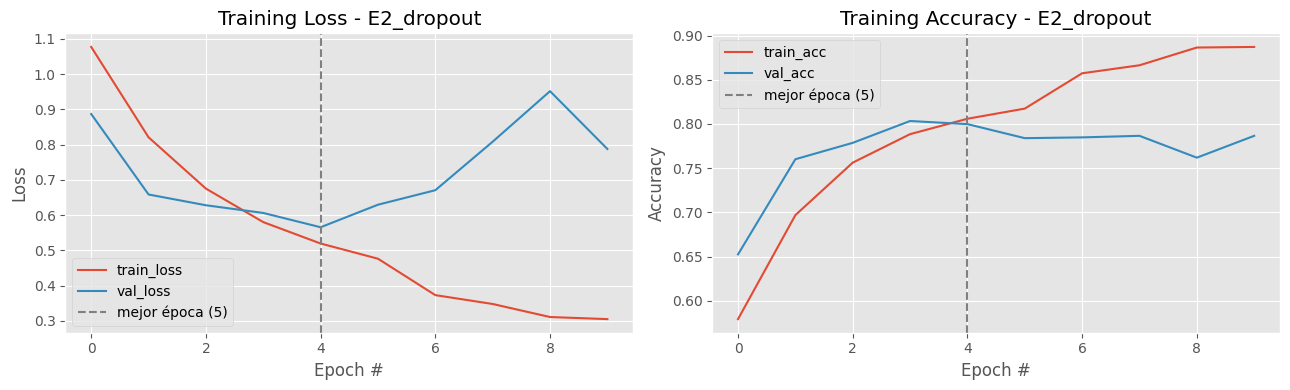

  experimento  épocas  train_acc  val_acc  val_loss
0     E1_base       8     0.8033   0.7875    0.6739
1  E2_dropout      10     0.8059   0.7998    0.5654


In [ ]:
model_2.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

print("[INFO]: Entrenando red neuronal...")
H = model_2.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                batch_size=32, epochs=30, callbacks=[parada()])
mostrar_resultados(H, "E2_dropout")

<p align="justify" style="text-align: justify;"><b>Análisis:</b> el <i>Dropout</i> <b>mejora el comportamiento</b> de la red respecto a E1. La pérdida de validación mínima baja de <b>0,67 a 0,57</b> y el <i>accuracy</i> de validación sube ligeramente, de <b>0,79 a 0,80</b>. Además, la mejor época pasa de la 3 a la <b>5</b>: al apagar neuronas al azar, la red tarda más en memorizar las imágenes de entrenamiento y puede aprender durante más épocas. En la mejor época, el <i>accuracy</i> de entrenamiento (0,81) y el de validación (0,80) son prácticamente iguales.
</p>

<p align="justify" style="text-align: justify;">Sin embargo, el sobreajuste no desaparece, como se ve en las dos gráficas:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b>Pérdida:</b> a partir de la época 5, la de entrenamiento sigue bajando (hasta 0,30), mientras que la de validación vuelve a subir, con un pico de <b>0,95</b> en la época 9.</li>
<li align="justify"><b><i>Accuracy</i>:</b> el de entrenamiento sigue subiendo hasta <b>0,89</b>, mientras que el de validación se estanca en torno a 0,76-0,79.</li>
</ul>

<p align="justify" style="text-align: justify;">Aun así, el sobreajuste es <b>más suave</b> que en E1: al final del entrenamiento, el <i>accuracy</i> de entrenamiento llega a 0,89 (frente a 0,97 en E1) y la pérdida de validación a 0,79 (frente a 1,31). El <i>Early Stopping</i> detuvo el entrenamiento en la época 10 y recuperó los pesos de la mejor época (la 5).
</p>

<p align="justify" style="text-align: justify;">Es decir, el <i>Dropout</i> <b>retrasa y reduce el sobreajuste, pero no lo elimina</b>. La causa principal sigue presente: unos <b>6,5 millones de parámetros</b> en la conexión entre <code>Flatten</code> y la capa densa, demasiados para 4.534 imágenes de entrenamiento.
</p>

<p align="justify" style="text-align: justify;"><b>Decisión para E3:</b> mantenemos el <i>Dropout</i> y sustituimos <code>Flatten</code> por <code>GlobalAveragePooling2D</code> para reducir drásticamente el número de parámetros.
</p>


### 2.3. Experimento E3: `GlobalAveragePooling2D` en lugar de `Flatten`

**Problema:** en E1 y E2 el modelo sobreajusta, y la causa principal es el **exceso de parámetros**. La capa `Flatten` convierte la salida de las convoluciones ($20 \times 20 \times 128$) en un vector de **51.200 valores**, y su conexión con la capa densa de 128 neuronas suma unos **6,5 millones de parámetros**, demasiados para 4.534 imágenes de entrenamiento.

`GlobalAveragePooling2D` calcula **la media de cada uno de los 128 mapas de características**. En lugar de mirar *dónde* aparece cada rasgo en la imagen, resume *si está presente*. Así, a la capa densa llegan solo **128 valores** y sus parámetros bajan a $128 \times 128 + 128 = 16.512$ (unas 400 veces menos).

Mantenemos el *Dropout* de E2 y cambiamos **solo** esta capa, para poder medir su efecto.

In [ ]:
tf.keras.utils.set_random_seed(42)

model_3 = Sequential()
model_3.add(layers.Input(shape=(TAMANO, TAMANO, 3)))
model_3.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu"))
model_3.add(layers.MaxPooling2D((2, 2)))
model_3.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu"))
model_3.add(layers.MaxPooling2D((2, 2)))
model_3.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu"))
model_3.add(layers.MaxPooling2D((2, 2)))
model_3.add(layers.GlobalAveragePooling2D())           # NUEVO (en lugar de Flatten)
model_3.add(layers.Dropout(0.5))
model_3.add(layers.Dense(128, activation="relu"))
model_3.add(layers.Dropout(0.5))
model_3.add(layers.Dense(len(clases), activation="softmax"))
model_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

[INFO]: Entrenando red neuronal...
Epoch 1/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 14s 68ms/step - accuracy: 0.4574 - loss: 1.3305 - val_accuracy: 0.5000 - val_loss: 1.1691
Epoch 2/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5437 - loss: 1.1525 - val_accuracy: 0.6332 - val_loss: 1.0327
Epoch 3/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.6048 - loss: 1.0443 - val_accuracy: 0.6781 - val_loss: 0.8954
Epoch 4/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.6339 - loss: 0.9930 - val_accuracy: 0.6305 - val_loss: 0.8875
Epoch 5/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.6476 - loss: 0.9542 - val_accuracy: 0.7055 - val_loss: 0.8246
Epoch 6/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.6661 - loss: 0.9138 - val_accuracy: 0.7178 - val_loss: 0.8074
Epoch 7/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.6707 - loss: 0.9029 - val_accuracy: 0.7125 - val_loss: 0.7900
Epoch 8/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accura

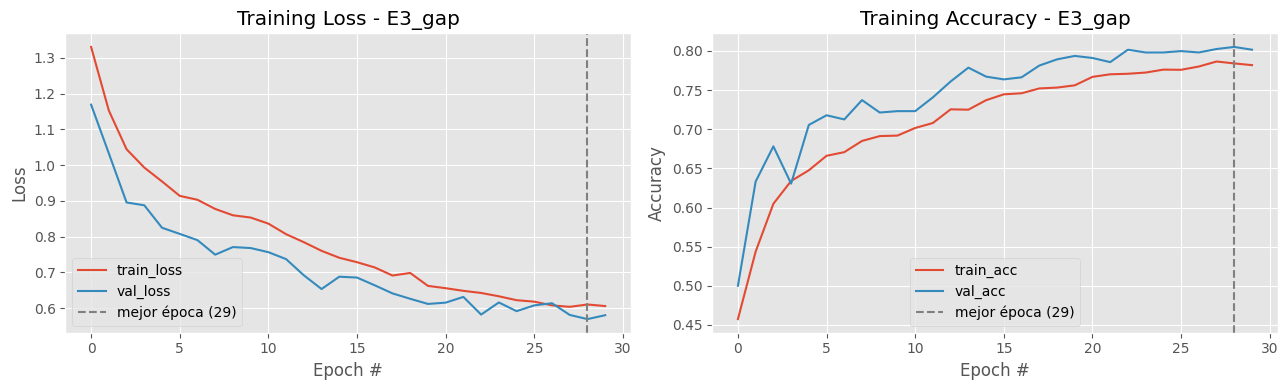

  experimento  épocas  train_acc  val_acc  val_loss
0     E1_base       8     0.8033   0.7875    0.6739
1  E2_dropout      10     0.8059   0.7998    0.5654
2      E3_gap      30     0.7841   0.8051    0.5690


In [ ]:
model_3.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

print("[INFO]: Entrenando red neuronal...")
H = model_3.fit(x_tr, y_tr, validation_data=(x_val, y_val),
          batch_size=32, epochs=30, callbacks=[parada()])
mostrar_resultados(H, "E3_gap")

<p align="justify" style="text-align: justify;"><b>Análisis:</b> sustituir <code>Flatten</code> por <code>GlobalAveragePooling2D</code> reduce el número de parámetros de unos <b>6,6 millones a unos 110.000</b> (unas 60 veces menos), y el comportamiento del modelo cambia por completo:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b>Desaparece el sobreajuste:</b> en las dos gráficas, las curvas de entrenamiento y validación avanzan juntas durante todo el entrenamiento. La pérdida de validación ya no se dispara como en E1 y E2, sino que baja de forma continua junto a la de entrenamiento. En la mejor época, el <i>accuracy</i> de validación (<b>0,81</b>) es incluso algo mayor que el de entrenamiento (0,78). Esto es habitual con <i>Dropout</i>, que solo está activo durante el entrenamiento.</li>
<li align="justify"><b>El rendimiento se mantiene:</b> el <i>accuracy</i> de validación (<b>0,81</b>) y la pérdida de validación (<b>0,57</b>) son prácticamente iguales a los de E2 (0,80 y 0,57), pero ahora con un modelo 60 veces más pequeño y sin sobreajuste.</li>
<li align="justify"><b>El modelo aprende mucho más despacio:</b> E2 alcanzaba su mejor resultado en la época 5, mientras que E3 necesita <b>29 épocas</b>.</li>
<li align="justify"><b>El entrenamiento no ha terminado:</b> la mejor época es la 29 de 30 y las curvas seguían mejorando al final, por lo que el <i>Early Stopping</i> no llegó a actuar. El modelo podría mejorar con más épocas.</li>
</ul>

<p align="justify" style="text-align: justify;">En resumen, con muchos menos parámetros obtenemos un rendimiento similar y <b>un modelo que generaliza mucho mejor</b>, aunque converge lentamente.
</p>

<p align="justify" style="text-align: justify;"><b>Decisión para E4:</b> mantenemos <code>GlobalAveragePooling2D</code> y <i>Dropout</i> y añadimos <i>Batch Normalization</i>, que normaliza las activaciones de cada capa y suele <b>acelerar la convergencia</b>, justo el problema que presenta E3. Además, aumentamos el máximo a <b>50 épocas</b>, porque E3 seguía mejorando al llegar a la época 30.
</p>


### 2.4. Experimento E4: *Batch Normalization*

**Problema:** en E3 el modelo generaliza bien, pero **aprende muy despacio**: necesitó las 30 épocas y todavía seguía mejorando. La *Batch Normalization* normaliza la salida de cada capa convolucional, lo que **estabiliza y acelera el entrenamiento**. También tiene un ligero efecto regularizador.

Mantenemos `GlobalAveragePooling2D` y *Dropout* de E3, y aumentamos el máximo a **50 épocas** porque E3 seguía mejorando al llegar a la época 30.

In [ ]:
tf.keras.utils.set_random_seed(42)   # misma semilla en cada experimento: resultados repetibles

model_4 = Sequential()
model_4.add(layers.Input(shape=(TAMANO, TAMANO, 3)))
model_4.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu"))
model_4.add(layers.BatchNormalization(momentum=0.9))   # NUEVO
model_4.add(layers.MaxPooling2D((2, 2)))
model_4.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu"))
model_4.add(layers.BatchNormalization(momentum=0.9))   # NUEVO
model_4.add(layers.MaxPooling2D((2, 2)))
model_4.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu"))
model_4.add(layers.BatchNormalization(momentum=0.9))   # NUEVO
model_4.add(layers.MaxPooling2D((2, 2)))
model_4.add(layers.GlobalAveragePooling2D())
model_4.add(layers.Dropout(0.5))
model_4.add(layers.Dense(128, activation="relu"))
model_4.add(layers.Dropout(0.5))
model_4.add(layers.Dense(len(clases), activation="softmax"))
model_4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,301 (434.77 KB)

 Trainable params: 110,853 (433.02 KB)

 Non-trainable params: 448 (1.75 KB)

[INFO]: Entrenando red neuronal...
Epoch 1/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 20s 89ms/step - accuracy: 0.5512 - loss: 1.2674 - val_accuracy: 0.6182 - val_loss: 0.9885
Epoch 2/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.6431 - loss: 0.9858 - val_accuracy: 0.6076 - val_loss: 1.1428
Epoch 3/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.6606 - loss: 0.9119 - val_accuracy: 0.6270 - val_loss: 1.2200
Epoch 4/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.6950 - loss: 0.8400 - val_accuracy: 0.5300 - val_loss: 2.2578
Epoch 5/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.7208 - loss: 0.7960 - val_accuracy: 0.6305 - val_loss: 1.2530
Epoch 6/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.7340 - loss: 0.7465 - val_accuracy: 0.6790 - val_loss: 0.9720
Epoch 7/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.7406 - loss: 0.7177 - val_accuracy: 0.5661 - val_loss: 1.3734
Epoch 8/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accur

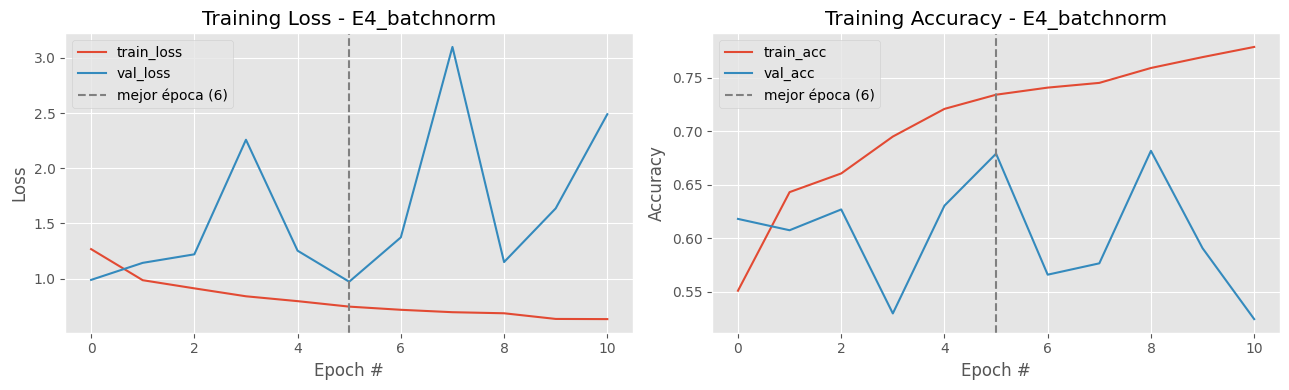

    experimento  épocas  train_acc  val_acc  val_loss
0       E1_base       8     0.8033   0.7875    0.6739
1    E2_dropout      10     0.8059   0.7998    0.5654
2        E3_gap      30     0.7841   0.8051    0.5690
3  E4_batchnorm      11     0.7340   0.6790    0.9720


In [ ]:
model_4.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

print("[INFO]: Entrenando red neuronal...")
H = model_4.fit(x_tr, y_tr, validation_data=(x_val, y_val),
          batch_size=32, epochs=50, callbacks=[parada()])
mostrar_resultados(H, "E4_batchnorm")

<p align="justify" style="text-align: justify;"><b>Análisis:</b> añadir <i>Batch Normalization</i> <b>empeora claramente el resultado</b>: el <i>accuracy</i> de validación baja de <b>0,81 (E3) a 0,68</b> y la pérdida de validación sube de 0,57 a <b>0,97</b>. El entrenamiento se detuvo en la época 11.
</p>

<p align="justify" style="text-align: justify;">Las dos gráficas muestran un comportamiento muy diferente entre entrenamiento y validación:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b>Entrenamiento:</b> las curvas son suaves. La pérdida baja de forma continua (hasta 0,63) y el <i>accuracy</i> sube poco a poco (hasta 0,78).</li>
<li align="justify"><b>Validación:</b> las curvas son <b>muy inestables</b>. La pérdida salta de 0,97 a <b>2,26</b> (época 4) y a <b>3,10</b> (época 8), y el <i>accuracy</i> sube y baja sin control, entre <b>0,52</b> y <b>0,68</b>.</li>
</ul>

<p align="justify" style="text-align: justify;">Debido a estas oscilaciones, el <i>Early Stopping</i> detuvo el entrenamiento en la época 11, cuando la red apenas había empezado a aprender, y recuperó los pesos de la época 6.
</p>

<p align="justify" style="text-align: justify;">La causa está en cómo funciona la <i>Batch Normalization</i>: durante el entrenamiento normaliza con la media y la varianza de cada lote, pero en validación utiliza una <b>media móvil</b> acumulada durante el entrenamiento. Mientras los pesos de la red cambian mucho, esa media no se ajusta bien, y la red, que funciona correctamente con las estadísticas de cada lote, se comporta de forma muy irregular con las acumuladas. Aunque usamos <code>momentum=0.9</code> para que la media se actualice más rápido, el problema persiste.
</p>

<p align="justify" style="text-align: justify;">Además, durante el desarrollo del trabajo observamos que <b>este mismo modelo daba resultados muy diferentes en distintas ejecuciones</b>, lo que confirma que, en nuestro problema, la <i>Batch Normalization</i> hace que el resultado dependa demasiado del azar.
</p>

<p align="justify" style="text-align: justify;"><b>Decisión para E5:</b> <b>descartamos la <i>Batch Normalization</i></b> y construimos E5 sobre E3, el mejor modelo estable hasta ahora, añadiendo <b>regularización L2</b>.
</p>


### 2.5. Experimento E5: regularización L2

**Problema:** en E4 comprobamos que la *Batch Normalization* hace inestable la validación, por lo que la descartamos y **partimos de E3**, el mejor modelo estable hasta ahora (`GlobalAveragePooling2D` + *Dropout*).

Añadimos **regularización L2** (*weight decay*) a las capas convolucionales y a la capa densa. La regularización L2 suma a la pérdida una penalización por el tamaño de los pesos:

$$\text{pérdida total} = \text{pérdida} + \lambda \sum w^2, \qquad \lambda = 0.0001$$

Así la red prefiere pesos pequeños y repartidos, en lugar de depender mucho de unas pocas conexiones, lo que suele mejorar la generalización.

In [ ]:
tf.keras.utils.set_random_seed(42)   # misma semilla en cada experimento: resultados repetibles
l2 = regularizers.l2(0.0001)         # lambda = 0.0001

model_5 = Sequential()
model_5.add(layers.Input(shape=(TAMANO, TAMANO, 3)))
# BASE MODEL
model_5.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu", kernel_regularizer=l2))   # NUEVO: L2
model_5.add(layers.MaxPooling2D((2, 2)))
model_5.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_regularizer=l2))   # NUEVO: L2
model_5.add(layers.MaxPooling2D((2, 2)))
model_5.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu", kernel_regularizer=l2))  # NUEVO: L2
model_5.add(layers.MaxPooling2D((2, 2)))
# TOP MODEL
model_5.add(layers.GlobalAveragePooling2D())
model_5.add(layers.Dropout(0.5))
model_5.add(layers.Dense(128, activation="relu", kernel_regularizer=l2))                           # NUEVO: L2
model_5.add(layers.Dropout(0.5))
model_5.add(layers.Dense(len(clases), activation="softmax"))
model_5.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

[INFO]: Entrenando red neuronal...
Epoch 1/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 14s 66ms/step - accuracy: 0.4521 - loss: 1.3488 - val_accuracy: 0.4947 - val_loss: 1.2078
Epoch 2/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.5315 - loss: 1.1793 - val_accuracy: 0.5503 - val_loss: 1.0469
Epoch 3/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.5902 - loss: 1.0764 - val_accuracy: 0.6402 - val_loss: 0.9402
Epoch 4/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.6171 - loss: 1.0366 - val_accuracy: 0.6146 - val_loss: 0.9177
Epoch 5/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.6398 - loss: 0.9907 - val_accuracy: 0.6905 - val_loss: 0.8665
Epoch 6/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.6511 - loss: 0.9627 - val_accuracy: 0.6966 - val_loss: 0.8911
Epoch 7/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.6601 - loss: 0.9530 - val_accuracy: 0.7108 - val_loss: 0.8238
Epoch 8/50
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accura

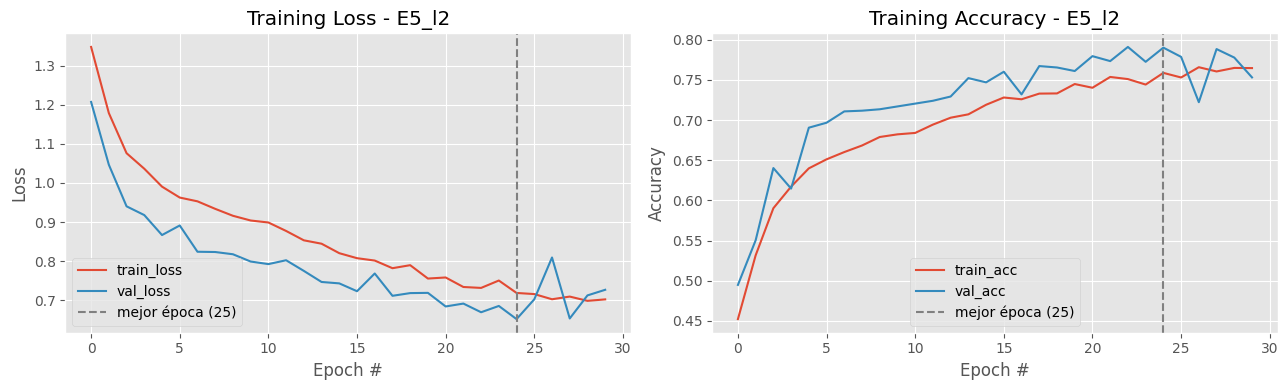

    experimento  épocas  train_acc  val_acc  val_loss
0       E1_base       8     0.8033   0.7875    0.6739
1    E2_dropout      10     0.8059   0.7998    0.5654
2        E3_gap      30     0.7841   0.8051    0.5690
3  E4_batchnorm      11     0.7340   0.6790    0.9720
4         E5_l2      30     0.7587   0.7901    0.6511


In [ ]:
model_5.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

print("[INFO]: Entrenando red neuronal...")
H = model_5.fit(x_tr, y_tr, validation_data=(x_val, y_val),
          batch_size=32, epochs=50, callbacks=[parada()])
mostrar_resultados(H, "E5_l2")

<p align="justify" style="text-align: justify;"><b>Análisis:</b> añadir regularización L2 <b>no mejora el resultado</b> respecto a E3. En la mejor época (la <b>25</b>), el <i>accuracy</i> de validación es de <b>≈ 0,79</b> (frente a 0,81 en E3) y la pérdida de validación de <b>≈ 0,65</b> (frente a 0,57). Hay que tener en cuenta que, con L2, la pérdida incluye la penalización $\lambda \sum w^2$, por lo que no es directamente comparable con la de E3. Aun así, el <i>accuracy</i> de validación también es algo menor.
</p>

<p align="justify" style="text-align: justify;">Las dos gráficas muestran un entrenamiento <b>estable y sin sobreajuste</b>:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b>Pérdida:</b> las curvas de entrenamiento y validación bajan juntas de forma continua hasta la época 25. A partir de ahí, la de validación empieza a oscilar (sube hasta 0,81 en la época 27).</li>
<li align="justify"><b><i>Accuracy</i>:</b> el de validación se mantiene por encima del de entrenamiento durante casi todo el entrenamiento (<b>≈ 0,79</b> frente a <b>≈ 0,76</b> en la mejor época), algo habitual con <i>Dropout</i>.</li>
</ul>

<p align="justify" style="text-align: justify;">El <i>Early Stopping</i> detuvo el entrenamiento en la época 30 y recuperó los pesos de la mejor época (la 25).
</p>

<p align="justify" style="text-align: justify;">La L2 penaliza los pesos grandes, pero nuestro modelo ya tenía pocos parámetros (unos 110.000) gracias a <code>GlobalAveragePooling2D</code> y ya estaba regularizado con <i>Dropout</i>. Por eso, añadir L2 <b>no aporta mejora</b>: el modelo no tenía un problema de sobreajuste que resolver.
</p>

<p align="justify" style="text-align: justify;"><b>Decisión para E6:</b> mantenemos la L2 y añadimos <i>data augmentation</i>, para comprobar si mostrar a la red imágenes más variadas mejora su capacidad de generalización.
</p>


### 2.6. Experimento E6: *Data Augmentation*

**Problema:** el modelo puede aprender detalles concretos de cada fotografía (encuadre, iluminación, fondo) en lugar de las características propias de la obra. Esto está directamente relacionado con nuestra pregunta de investigación: queremos que la red reconozca el tipo de obra y no la forma en que fue fotografiada.

Con el *data augmentation*, en cada época la red ve versiones algo distintas de cada imagen: **volteo horizontal**, **pequeñas rotaciones** (hasta ±18°) y **zoom** (hasta ±10 %). Estas transformaciones simulan distintas formas de fotografiar la misma obra sin cambiar su categoría. Las capas de aumento **solo actúan durante el entrenamiento**: en validación y test, la red ve las imágenes originales.

No usamos volteo vertical ni rotaciones grandes, porque una obra boca abajo no es una imagen realista.

Partimos de **E5** (`GlobalAveragePooling2D` + *Dropout* + L2) y añadimos solo el *data augmentation*. Como E5 seguía mejorando al llegar a la época 50, aumentamos el máximo a **80 épocas**.


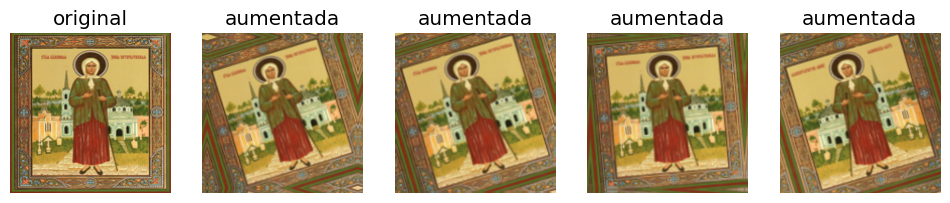

In [ ]:
tf.keras.utils.set_random_seed(42)

data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),   # volteo horizontal (espejo)
    layers.RandomRotation(0.05),       # rotación de hasta ±18° (0.05 x 360°)
    layers.RandomZoom(0.1),            # zoom de hasta ±10 %
])

plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    img = x_tr[:1] if i == 0 else data_augmentation(x_tr[:1], training=True)
    plt.imshow(np.array(img[0]))
    plt.title("original" if i == 0 else "aumentada")
    plt.axis("off")
plt.show()

In [ ]:
tf.keras.utils.set_random_seed(42)   # misma semilla en cada experimento: resultados repetibles

model_6 = Sequential()
model_6.add(layers.Input(shape=(TAMANO, TAMANO, 3)))
model_6.add(data_augmentation)                                                                     # NUEVO
# BASE MODEL
model_6.add(layers.Conv2D(32, (3, 3), padding="same", activation="relu", kernel_regularizer=l2))
model_6.add(layers.MaxPooling2D((2, 2)))
model_6.add(layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_regularizer=l2))
model_6.add(layers.MaxPooling2D((2, 2)))
model_6.add(layers.Conv2D(128, (3, 3), padding="same", activation="relu", kernel_regularizer=l2))
model_6.add(layers.MaxPooling2D((2, 2)))
# TOP MODEL
model_6.add(layers.GlobalAveragePooling2D())
model_6.add(layers.Dropout(0.5))
model_6.add(layers.Dense(128, activation="relu", kernel_regularizer=l2))
model_6.add(layers.Dropout(0.5))
model_6.add(layers.Dense(len(clases), activation="softmax"))
model_6.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_5 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

[INFO]: Entrenando red neuronal...
Epoch 1/80
142/142 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - accuracy: 0.4554 - loss: 1.3412 - val_accuracy: 0.5000 - val_loss: 1.1816
Epoch 2/80
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.5368 - loss: 1.1786 - val_accuracy: 0.6102 - val_loss: 1.0259
Epoch 3/80
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.5723 - loss: 1.1096 - val_accuracy: 0.6235 - val_loss: 0.9613
Epoch 4/80
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5948 - loss: 1.0695 - val_accuracy: 0.6772 - val_loss: 0.9405
Epoch 5/80
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.6142 - loss: 1.0256 - val_accuracy: 0.6543 - val_loss: 0.9261
Epoch 6/80
142/142 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.6273 - loss: 0.9966 - val_accuracy: 0.6755 - val_loss: 0.8925
Epoch 7/80
142/142 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.6376 - loss: 0.9864 - val_accuracy: 0.6746 - val_loss: 0.9098
Epoch 8/80
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accura

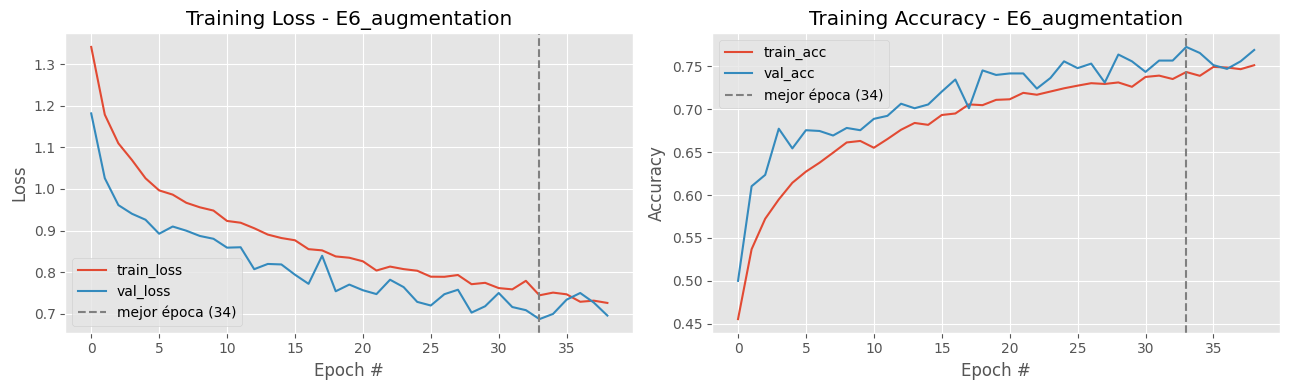

       experimento  épocas  train_acc  val_acc  val_loss
0          E1_base       8     0.8033   0.7875    0.6739
1       E2_dropout      10     0.8059   0.7998    0.5654
2           E3_gap      30     0.7841   0.8051    0.5690
3     E4_batchnorm      11     0.7340   0.6790    0.9720
4            E5_l2      30     0.7587   0.7901    0.6511
5  E6_augmentation      39     0.7433   0.7725    0.6874


In [ ]:
model_6.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

print("[INFO]: Entrenando red neuronal...")
H = model_6.fit(x_tr, y_tr, validation_data=(x_val, y_val),
          batch_size=32, epochs=80, callbacks=[parada()])
mostrar_resultados(H, "E6_augmentation")

<p align="justify" style="text-align: justify;"><b>Análisis:</b> añadir <i>data augmentation</i> <b>empeora el resultado</b>: el <i>accuracy</i> de validación baja a <b>0,77</b> (frente a 0,79 en E5 y 0,81 en E3) y la pérdida de validación sube a <b>0,69</b> (frente a 0,65 en E5). El <i>Early Stopping</i> detuvo el entrenamiento en la época 39 y recuperó los pesos de la mejor época (la 34).
</p>

<p align="justify" style="text-align: justify;">Las dos gráficas muestran que <b>no hay sobreajuste</b>: las curvas de entrenamiento y validación avanzan juntas y el <i>accuracy</i> de validación (0,77) es incluso mayor que el de entrenamiento (0,74). El problema es el contrario, un <b>subajuste</b>: el <i>accuracy</i> de entrenamiento se queda en <b>0,74</b>, el valor más bajo de todos los experimentos estables, por lo que la red no llega a aprender bien ni siquiera las imágenes de entrenamiento. Además, aprende muy despacio: necesita 34 épocas para alcanzar su mejor resultado.
</p>

<p align="justify" style="text-align: justify;">La causa es un <b>exceso de regularización</b>. E6 combina <i>Dropout</i> del 50 %, regularización L2, una red con pocos parámetros (unos 110.000, gracias a <code>GlobalAveragePooling2D</code>) y, además, imágenes de entrenamiento que cambian en cada época. Cada una de estas técnicas frena el aprendizaje, y juntas lo frenan demasiado.
</p>

<p align="justify" style="text-align: justify;">Con nuestro modelo, por tanto, el <i>data augmentation</i> no aporta mejora. Para aprovecharlo habría que compensar la regularización, por ejemplo reduciendo el <i>Dropout</i> o aumentando la capacidad de la red. Lo dejamos como posible mejora futura.
</p>


### 2.7. Comparación de los experimentos y elección de nuestra CNN

Reunimos los resultados de los seis experimentos para compararlos y elegir el mejor modelo de la estrategia 1. El criterio principal es el **_accuracy_ de validación**, pero también tenemos en cuenta la **estabilidad de las curvas** y la **diferencia entre entrenamiento y validación** (sobreajuste). El conjunto de **test** no interviene en esta decisión: se usará en el apartado 4.

       experimento  épocas  train_acc  val_acc  val_loss  \
0          E1_base       8     0.8033   0.7875    0.6739   
1       E2_dropout      10     0.8059   0.7998    0.5654   
2           E3_gap      30     0.7841   0.8051    0.5690   
3     E4_batchnorm      11     0.7340   0.6790    0.9720   
4            E5_l2      30     0.7587   0.7901    0.6511   
5  E6_augmentation      39     0.7433   0.7725    0.6874   

   diferencia (train - val)  
0                    0.0158  
1                    0.0061  
2                   -0.0210  
3                    0.0550  
4                   -0.0314  
5                   -0.0292  


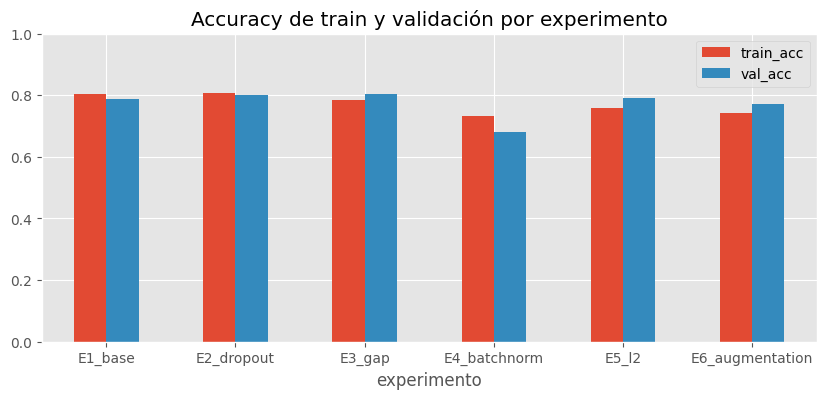

In [ ]:
tabla_cnn = pd.DataFrame(resultados)
tabla_cnn["diferencia (train - val)"] = (tabla_cnn["train_acc"] - tabla_cnn["val_acc"]).round(4)
print(tabla_cnn)

tabla_cnn.plot(x="experimento", y=["train_acc", "val_acc"], kind="bar", figsize=(10, 4))
plt.title("Accuracy de train y validación por experimento")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

In [ ]:
# Diccionario con los modelos de cada experimento
modelos_cnn = {"E1_base": model_1, "E2_dropout": model_2, "E3_gap": model_3,
               "E4_batchnorm": model_4, "E5_l2": model_5, "E6_augmentation": model_6}

# Elegimos el experimento con mayor accuracy de validación
mejor_nombre = tabla_cnn.loc[tabla_cnn["val_acc"].idxmax(), "experimento"]
mejor_cnn = modelos_cnn[mejor_nombre]
mejor_cnn.save("mejor_cnn.keras")
print("Mejor CNN:", mejor_nombre)

Mejor CNN: E3_gap


**Conclusión de la estrategia 1:** elegimos el modelo **E3** (`GlobalAveragePooling2D` + *Dropout*) como nuestra mejor CNN desde cero, por tres motivos:

1. **Mayor *accuracy* de validación** de todos los experimentos: **0,81**, con una de las pérdidas de validación más bajas (**0,57**).
2. **Sin sobreajuste**: las curvas de entrenamiento y validación avanzan juntas, y el *accuracy* de validación (0,81) es incluso algo mayor que el de entrenamiento (0,78).
3. **Modelo ligero**: unos 110.000 parámetros, frente a los 6,6 millones de la red base.

Para comprobar que el modelo ha aprendido patrones reales, lo comparamos con dos clasificadores triviales. Elegir una clase al azar acertaría el 20 % de las veces ($1/5$), y predecir siempre la clase más frecuente (*iconography*) acertaría un **32 %** ($368/1.134$ en validación). Nuestro modelo alcanza un **81 %**, muy por encima de ambos.

**Efecto de cada técnica en nuestro problema:**

| Experimento | Técnica | `val_acc` | Efecto |
|---|---|---|---|
| E1 | Red base | 0,79 | Sobreajuste fuerte desde la época 3 |
| E2 | *Dropout* | 0,80 | ✅ Retrasa y reduce el sobreajuste, pero no lo elimina |
| E3 | `GlobalAveragePooling2D` | **0,81** | ✅ **Elimina el sobreajuste** con 60 veces menos parámetros |
| E4 | *Batch Normalization* | 0,68 | ❌ Validación muy inestable y resultados poco reproducibles |
| E5 | Regularización L2 | 0,79 | ➖ Estable, pero sin mejora: el modelo ya estaba suficientemente regularizado |
| E6 | *Data Augmentation* | 0,77 | ❌ Exceso de regularización: subajuste |

La técnica decisiva fue **reducir el número de parámetros** (E3): el sobreajuste de la red base se debía sobre todo a los 6,5 millones de parámetros de la capa densa. A partir de ahí, añadir más regularización (L2 y *data augmentation*) no mejoró el modelo, e incluso lo llevó al **subajuste**. La lección principal es que **no basta con acumular técnicas de regularización**: cada una debe resolver un problema observado en el experimento anterior, y añadir demasiadas puede llevar del sobreajuste al subajuste.

**Limitación:** E3 seguía mejorando al llegar a la época 30, por lo que con más épocas podría mejorar algo más. Además, el tope no es el mismo en los seis experimentos: E1, E2 y E3 llegan a 30, E4 y E5 a 50, y E6 a 80. El tope se subió porque vimos que el experimento anterior seguía mejorando al llegar al límite, así que la comparación no parte del mismo margen de entrenamiento. La evaluación final con el conjunto de test se realiza en el apartado 4.

<a id="3"></a>
# 3. Estrategia 2: redes preentrenadas (*transfer learning* y *fine-tuning*)

Utilizamos dos redes preentrenadas en **ImageNet** (1,2 millones de imágenes de 1.000 categorías) y las adaptamos a nuestro problema. Elegimos dos arquitecturas de naturaleza distinta:

- **MobileNetV2:** red ligera (unos 2,3 millones de parámetros), pensada para dispositivos con pocos recursos. Además, 160×160 es uno de los tamaños con los que fue entrenada.
- **ResNet50:** red profunda (unos 23,5 millones de parámetros) con conexiones residuales, que suele ser más precisa pero es más pesada.

Para cada red seguimos dos pasos:
1. ***Transfer learning*:** congelamos la red preentrenada (base) y entrenamos solo una nueva parte final (cabeza) para nuestras 5 clases. Usamos las características que la red ya aprendió en ImageNet.
2. ***Fine-tuning*:** descongelamos el **20 % final** de la base y la reentrenamos con una tasa de aprendizaje **100 veces menor** (0,00001), para ajustar sus pesos a las obras de arte sin destruir lo aprendido.

**Decisiones basadas en la estrategia 1:**
- **No usamos *data augmentation*,** porque en E6 provocó subajuste.
- **Durante el *fine-tuning* mantenemos congeladas las capas de *Batch Normalization*,** porque en E4 vimos que hacían inestable la validación.
- Usamos *Dropout* (0,3) en la cabeza para reducir el sobreajuste.

### 3.1. Preparación

Cada red preentrenada espera los píxeles en una escala concreta, la misma que se usó al entrenarla en ImageNet. Nuestras imágenes ya están en el rango 0-1, así que añadimos una capa al principio de cada modelo que las convierte:
- **MobileNetV2** espera valores entre -1 y 1: $x' = 2x - 1$.
- **ResNet50** espera valores entre 0 y 255, con los canales en orden BGR y restando la media de ImageNet. Lo hace su función `preprocess_input`.

También creamos una función que descongela el 20 % final de la base sin tocar las capas de *Batch Normalization*.

In [ ]:
from tensorflow.keras.applications import MobileNetV2, ResNet50

def descongelar(base, porcentaje):
    # Descongela el porcentaje final de capas de la base, excepto las de BatchNormalization
    base.trainable = True
    inicio = int(len(base.layers) * (1 - porcentaje))
    for i, capa in enumerate(base.layers):
        capa.trainable = (i >= inicio) and not isinstance(capa, layers.BatchNormalization)
    print("Capas entrenables:", sum(c.trainable for c in base.layers), "de", len(base.layers))

### 3.2. MobileNetV2

#### 3.2.1. *Transfer learning*

Congelamos toda la base y entrenamos solo la cabeza: `GlobalAveragePooling2D` → `Dropout(0.3)` → `Dense(5, softmax)`.

In [ ]:
tf.keras.utils.set_random_seed(42)

# BASE MODEL: MobileNetV2 preentrenada en ImageNet, sin su parte de clasificación
base_mobile = MobileNetV2(weights="imagenet", include_top=False, input_shape=(TAMANO, TAMANO, 3))
base_mobile.trainable = False      # TRANSFER LEARNING: congelamos la base

model_mobile = Sequential()
model_mobile.add(layers.Input(shape=(TAMANO, TAMANO, 3)))
model_mobile.add(layers.Rescaling(2.0, offset=-1.0))      # de [0, 1] a [-1, 1]
model_mobile.add(base_mobile)
# TOP MODEL: nueva cabeza para nuestras 5 clases
model_mobile.add(layers.GlobalAveragePooling2D())
model_mobile.add(layers.Dropout(0.3))
model_mobile.add(layers.Dense(len(clases), activation="softmax"))
model_mobile.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

[INFO]: Entrenando MobileNetV2 (transfer learning)...
Epoch 1/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 65s 304ms/step - accuracy: 0.7552 - loss: 0.6665 - val_accuracy: 0.8721 - val_loss: 0.3364
Epoch 2/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.8659 - loss: 0.3590 - val_accuracy: 0.8924 - val_loss: 0.2830
Epoch 3/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.8822 - loss: 0.3019 - val_accuracy: 0.8898 - val_loss: 0.2646
Epoch 4/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9016 - loss: 0.2551 - val_accuracy: 0.8959 - val_loss: 0.2569
Epoch 5/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9120 - loss: 0.2328 - val_accuracy: 0.9048 - val_loss: 0.2482
Epoch 6/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9175 - loss: 0.2141 - val_accuracy: 0.9109 - val_loss: 0.2426
Epoch 7/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9162 - loss: 0.2105 - val_accuracy: 0.9083 - val_loss: 0.2418
Epoch 8/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4

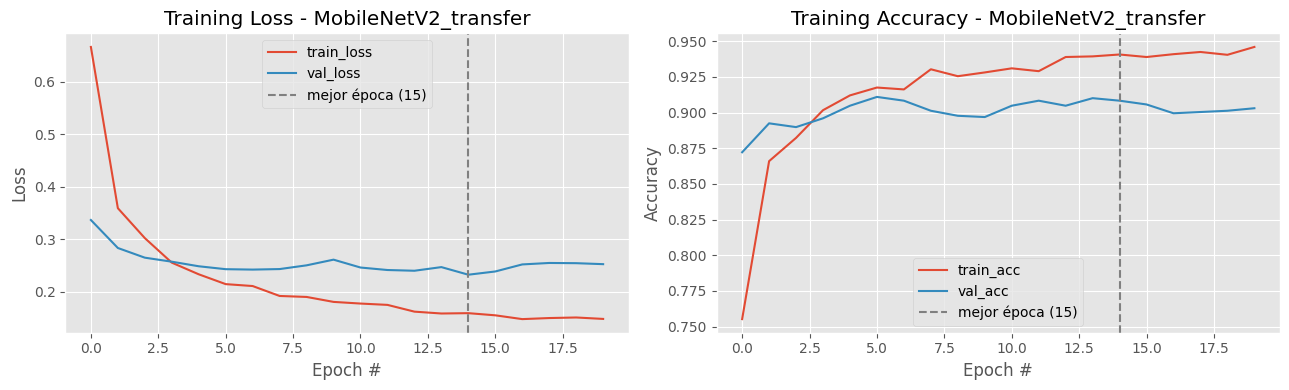

            experimento  épocas  train_acc  val_acc  val_loss
0               E1_base       8     0.8033   0.7875    0.6739
1            E2_dropout      10     0.8059   0.7998    0.5654
2                E3_gap      30     0.7841   0.8051    0.5690
3          E4_batchnorm      11     0.7340   0.6790    0.9720
4                 E5_l2      30     0.7587   0.7901    0.6511
5       E6_augmentation      39     0.7433   0.7725    0.6874
6  MobileNetV2_transfer      20     0.9407   0.9083    0.2321


In [ ]:
model_mobile.compile(optimizer=Adam(learning_rate=0.001),
                     loss="sparse_categorical_crossentropy",
                     metrics=["accuracy"])

print("[INFO]: Entrenando MobileNetV2 (transfer learning)...")
H = model_mobile.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                     batch_size=32, epochs=30, callbacks=[parada()])
mostrar_resultados(H, "MobileNetV2_transfer")

<p align="justify" style="text-align: justify;"><b>Análisis:</b> el <i>transfer learning</i> con MobileNetV2 <b>supera claramente a nuestra mejor CNN desde cero</b>: el <i>accuracy</i> de validación sube de <b>0,81 (E3) a 0,91</b> y la pérdida de validación baja de 0,57 a <b>0,23</b>, unas 2,5 veces menos. Y lo consigue entrenando solo unos <b>6.400 parámetros</b> (la nueva cabeza), frente a los 110.000 de E3.
</p>

<p align="justify" style="text-align: justify;">Las dos gráficas muestran un aprendizaje <b>muy rápido</b>:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b><i>Accuracy</i>:</b> ya en la primera época, el <i>accuracy</i> de validación es de <b>0,87</b>, más alto que el que alcanzó E3 tras 29 épocas.</li>
<li align="justify"><b>Pérdida:</b> la de validación baja rápidamente hasta unos 0,24 en la época 5 y, a partir de ahí, se mantiene prácticamente <b>plana</b>.</li>
</ul>

<p align="justify" style="text-align: justify;">Esto se debe a que la base de MobileNetV2 ya sabe detectar bordes, texturas, formas y objetos gracias a su entrenamiento en ImageNet, y esas características también sirven para distinguir tipos de obras de arte.
</p>

<p align="justify" style="text-align: justify;">A partir de la época 5, la validación se <b>estanca</b> (<i>accuracy</i> en torno a 0,90-0,91), mientras que el entrenamiento sigue mejorando: su pérdida baja hasta 0,15 y su <i>accuracy</i> sube hasta 0,95. Aparece, por tanto, un <b>ligero sobreajuste</b>: la diferencia entre entrenamiento y validación es de unos 3 puntos, pequeña y estable. El <i>Early Stopping</i> detuvo el entrenamiento en la época 20 y recuperó los pesos de la mejor época (la 15).
</p>

<p align="justify" style="text-align: justify;">Con la base congelada, la cabeza ya no puede mejorar más: las características de ImageNet están limitadas a lo que la red aprendió con fotografías de objetos cotidianos.
</p>

<p align="justify" style="text-align: justify;"><b>Decisión para el <i>fine-tuning</i>:</b> descongelamos el 20 % final de la base para adaptar sus características a las obras de arte.
</p>


Capas entrenables: 20 de 154


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 1,609,285 (6.14 MB)

 Non-trainable params: 655,104 (2.50 MB)

[INFO]: Entrenando MobileNetV2 (fine-tuning)...
Epoch 1/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 34s 124ms/step - accuracy: 0.9365 - loss: 0.1581 - val_accuracy: 0.9039 - val_loss: 0.2444
Epoch 2/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9543 - loss: 0.1169 - val_accuracy: 0.9127 - val_loss: 0.2387
Epoch 3/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9643 - loss: 0.1011 - val_accuracy: 0.9101 - val_loss: 0.2349
Epoch 4/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9727 - loss: 0.0801 - val_accuracy: 0.9145 - val_loss: 0.2544
Epoch 5/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9768 - loss: 0.0709 - val_accuracy: 0.9048 - val_loss: 0.2339
Epoch 6/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9790 - loss: 0.0621 - val_accuracy: 0.9136 - val_loss: 0.2718
Epoch 7/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9806 - loss: 0.0547 - val_accuracy: 0.9118 - val_loss: 0.2363
Epoch 8/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms

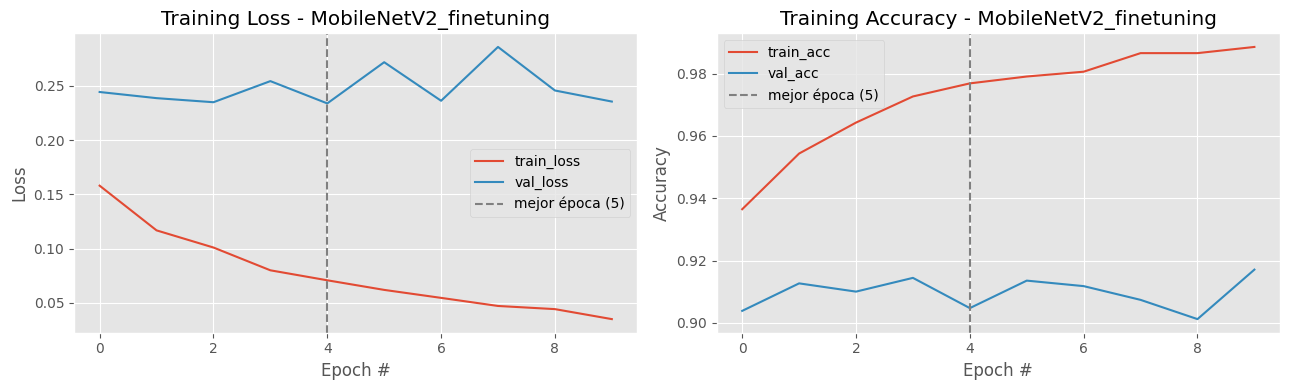

              experimento  épocas  train_acc  val_acc  val_loss
0                 E1_base       8     0.8033   0.7875    0.6739
1              E2_dropout      10     0.8059   0.7998    0.5654
2                  E3_gap      30     0.7841   0.8051    0.5690
3            E4_batchnorm      11     0.7340   0.6790    0.9720
4                   E5_l2      30     0.7587   0.7901    0.6511
5         E6_augmentation      39     0.7433   0.7725    0.6874
6    MobileNetV2_transfer      20     0.9407   0.9083    0.2321
7  MobileNetV2_finetuning      10     0.9768   0.9048    0.2339


In [ ]:
descongelar(base_mobile, 0.20)

# Hay que volver a compilar después de cambiar qué capas se entrenan
model_mobile.compile(optimizer=Adam(learning_rate=0.00001),
                     loss="sparse_categorical_crossentropy",
                     metrics=["accuracy"])
model_mobile.summary()

print("[INFO]: Entrenando MobileNetV2 (fine-tuning)...")
H = model_mobile.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                     batch_size=32, epochs=30, callbacks=[parada()])
mostrar_resultados(H, "MobileNetV2_finetuning")

<p align="justify" style="text-align: justify;"><b>Análisis:</b> el <i>fine-tuning</i> <b>no mejora</b> el resultado del <i>transfer learning</i>. El <i>accuracy</i> de validación se mantiene en <b>0,90</b> (0,9048 frente a 0,9083) y la pérdida de validación en <b>0,23</b> (0,2339 frente a 0,2321).
</p>

<p align="justify" style="text-align: justify;">Las dos gráficas muestran por qué:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b>Validación:</b> las curvas son prácticamente <b>planas</b>. El <i>accuracy</i> oscila entre 0,90 y 0,92 y la pérdida entre 0,23 y 0,29, sin una tendencia de mejora.</li>
<li align="justify"><b>Entrenamiento:</b> en cambio, mejora mucho. El <i>accuracy</i> sube de 0,94 a <b>0,99</b> y la pérdida baja de 0,16 a <b>0,04</b>.</li>
</ul>

<p align="justify" style="text-align: justify;">Es decir, la red utiliza los <b>1,6 millones de parámetros</b> que hemos descongelado para <b>memorizar las imágenes de entrenamiento</b>, no para generalizar mejor. La diferencia entre el <i>accuracy</i> de entrenamiento y el de validación pasa de unos <b>3 puntos</b> (<i>transfer learning</i>: 0,94 frente a 0,91) a unos <b>7 puntos</b> (<i>fine-tuning</i>: 0,98 frente a 0,90): <b>aumenta el sobreajuste</b>. El <i>Early Stopping</i> detuvo el entrenamiento en la época 10 y recuperó los pesos de la época 5.
</p>

<p align="justify" style="text-align: justify;">Una posible explicación es que las características que MobileNetV2 aprendió en ImageNet (bordes, texturas, formas) <b>ya son suficientes</b> para distinguir nuestras cinco categorías, y que nuestro conjunto de entrenamiento (4.534 imágenes) es demasiado pequeño para ajustar 1,6 millones de parámetros sin sobreajustar, incluso con una tasa de aprendizaje muy baja (0,00001).
</p>

<p align="justify" style="text-align: justify;"><b>Conclusión para MobileNetV2:</b> el <i>transfer learning</i> es suficiente; el <i>fine-tuning</i> añade coste de cálculo y sobreajuste sin mejorar la validación.
</p>


### 3.3. ResNet50

#### 3.3.1. *Transfer learning*

Repetimos el mismo proceso con ResNet50, sin cambiar los datos ni la cabeza, para comparar las dos arquitecturas en igualdad de condiciones.

In [ ]:
tf.keras.utils.set_random_seed(42)

base_resnet = ResNet50(weights="imagenet", include_top=False, input_shape=(TAMANO, TAMANO, 3))
base_resnet.trainable = False      # TRANSFER LEARNING: congelamos la base

model_resnet = Sequential()
model_resnet.add(layers.Input(shape=(TAMANO, TAMANO, 3)))
# Preprocesado de ResNet50: de [0, 1] a [0, 255], orden BGR y restar la media de ImageNet
model_resnet.add(layers.Lambda(lambda x: tf.keras.applications.resnet50.preprocess_input(x * 255.0)))
model_resnet.add(base_resnet)
model_resnet.add(layers.GlobalAveragePooling2D())
model_resnet.add(layers.Dropout(0.3))
model_resnet.add(layers.Dense(len(clases), activation="softmax"))
model_resnet.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 5, 5, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
resultados = [r for r in resultados if not r["experimento"].startswith("ResNet50")]

[INFO]: Entrenando ResNet50 (transfer learning)...
Epoch 1/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 69s 309ms/step - accuracy: 0.7819 - loss: 0.6173 - val_accuracy: 0.8977 - val_loss: 0.2824
Epoch 2/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.8917 - loss: 0.3040 - val_accuracy: 0.8924 - val_loss: 0.2842
Epoch 3/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.9060 - loss: 0.2486 - val_accuracy: 0.9127 - val_loss: 0.2396
Epoch 4/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 10s 70ms/step - accuracy: 0.9257 - loss: 0.1969 - val_accuracy: 0.9136 - val_loss: 0.2425
Epoch 5/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.9307 - loss: 0.1812 - val_accuracy: 0.9048 - val_loss: 0.2448
Epoch 6/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.9338 - loss: 0.1676 - val_accuracy: 0.9039 - val_loss: 0.2638
Epoch 7/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.9389 - loss: 0.1634 - val_accuracy: 0.9048 - val_loss: 0.2692
Epoch 8/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 8s 

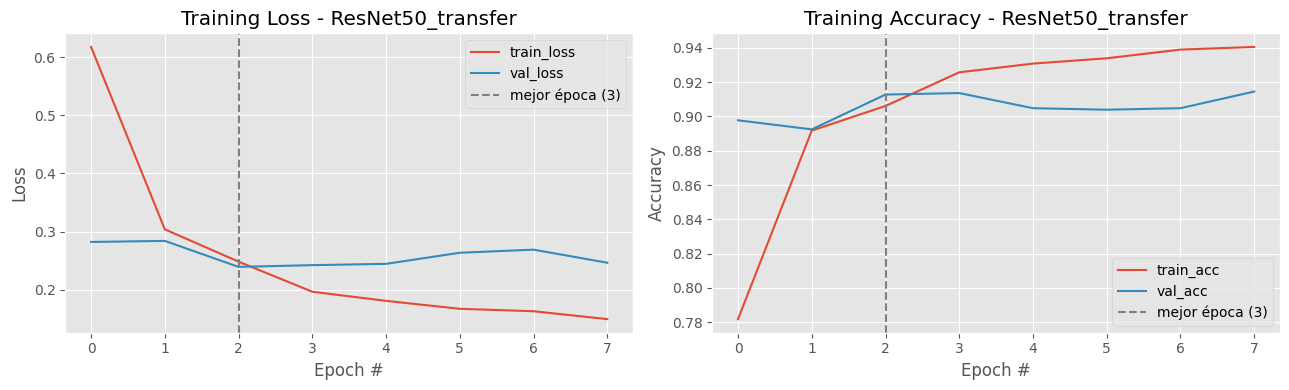

              experimento  épocas  train_acc  val_acc  val_loss
0                 E1_base       8     0.8033   0.7875    0.6739
1              E2_dropout      10     0.8059   0.7998    0.5654
2                  E3_gap      30     0.7841   0.8051    0.5690
3            E4_batchnorm      11     0.7340   0.6790    0.9720
4                   E5_l2      30     0.7587   0.7901    0.6511
5         E6_augmentation      39     0.7433   0.7725    0.6874
6    MobileNetV2_transfer      20     0.9407   0.9083    0.2321
7  MobileNetV2_finetuning      10     0.9768   0.9048    0.2339
8       ResNet50_transfer       8     0.9060   0.9127    0.2396


In [ ]:
model_resnet.compile(optimizer=Adam(learning_rate=0.001),
                     loss="sparse_categorical_crossentropy",
                     metrics=["accuracy"])

print("[INFO]: Entrenando ResNet50 (transfer learning)...")
H = model_resnet.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                     batch_size=32, epochs=30, callbacks=[parada()])
mostrar_resultados(H, "ResNet50_transfer")
pesos_resnet_transfer = model_resnet.get_weights()   # guardamos los pesos del transfer learning

<p align="justify" style="text-align: justify;"><b>Análisis:</b> el <i>transfer learning</i> con ResNet50 obtiene un <i>accuracy</i> de validación de <b>0,91</b> (0,9127) y una pérdida de validación de <b>0,24</b>, resultados <b>prácticamente iguales a los de MobileNetV2</b> (0,9083 y 0,23). ResNet50 acierta algo más, pero la diferencia es de menos de medio punto, unas 5 imágenes de las 1.134 de validación, y MobileNetV2 tiene una pérdida algo menor. Podemos considerar que ambas redes empatan. Frente a nuestra mejor CNN desde cero (E3, con 0,81), la mejora es de unos <b>11 puntos</b>.
</p>

<p align="justify" style="text-align: justify;">Las dos gráficas muestran que ResNet50 aprende <b>todavía más rápido</b> que MobileNetV2:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b><i>Accuracy</i>:</b> en la primera época, el de validación ya es de <b>0,90</b>, y su mejor resultado llega en la época <b>3</b>.</li>
<li align="justify"><b>Pérdida:</b> la de validación es baja desde el principio (0,28) y alcanza su mínimo (0,24) en la época 3.</li>
</ul>

<p align="justify" style="text-align: justify;">En la mejor época <b>no hay sobreajuste</b>: el <i>accuracy</i> de entrenamiento (0,91) y el de validación (0,91) son prácticamente iguales. En las épocas siguientes, el entrenamiento sigue mejorando (<i>accuracy</i> de hasta 0,94 y pérdida de hasta 0,15), mientras que la validación se estanca y su pérdida sube ligeramente (hasta 0,27). Por eso el <i>Early Stopping</i> detuvo el entrenamiento en la época 8 y recuperó los pesos de la época 3.
</p>

<p align="justify" style="text-align: justify;">El principal inconveniente de ResNet50 es su <b>coste</b>: su base tiene unos 23,6 millones de parámetros, unas 10 veces más que MobileNetV2, y cada época tarda aproximadamente el doble (unos 8 segundos frente a 4). Para un resultado equivalente, MobileNetV2 es mucho más eficiente.
</p>

<p align="justify" style="text-align: justify;"><b>Decisión para el <i>fine-tuning</i>:</b> igual que con MobileNetV2, descongelamos el 20 % final de la base para comprobar si podemos mejorar el resultado.
</p>


#### 3.3.2. *Fine-tuning*

Capas entrenables: 24 de 175


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 5, 5, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 14,963,717 (57.08 MB)

 Non-trainable params: 8,634,240 (32.94 MB)

[INFO]: Entrenando ResNet50 (fine-tuning)...
Epoch 1/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 45s 193ms/step - accuracy: 0.9277 - loss: 0.1840 - val_accuracy: 0.9092 - val_loss: 0.2259
Epoch 2/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.9603 - loss: 0.1129 - val_accuracy: 0.9118 - val_loss: 0.2336
Epoch 3/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - accuracy: 0.9764 - loss: 0.0659 - val_accuracy: 0.9189 - val_loss: 0.2432
Epoch 4/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 21s 88ms/step - accuracy: 0.9868 - loss: 0.0435 - val_accuracy: 0.9118 - val_loss: 0.2561
Epoch 5/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.9929 - loss: 0.0247 - val_accuracy: 0.9198 - val_loss: 0.2649
Epoch 6/30
142/142 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - accuracy: 0.9954 - loss: 0.0176 - val_accuracy: 0.9250 - val_loss: 0.2765
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.


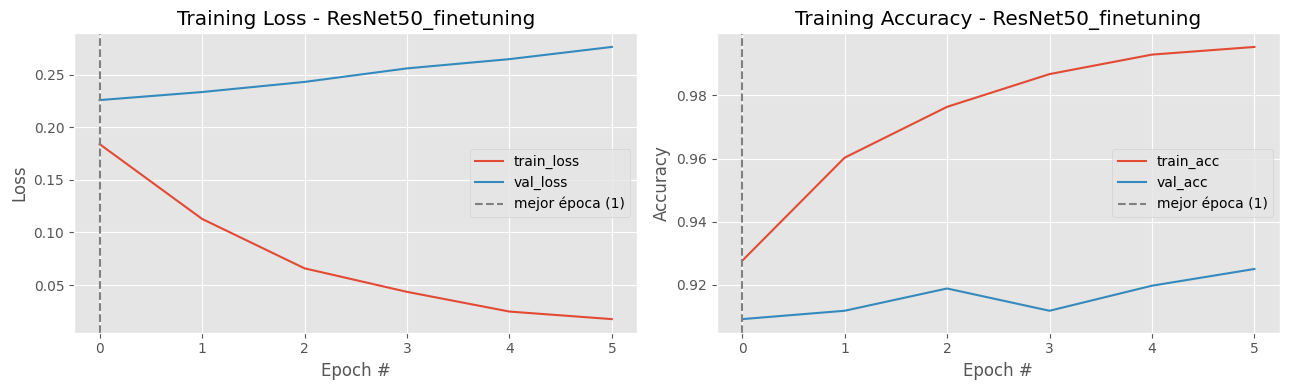

              experimento  épocas  train_acc  val_acc  val_loss
0                 E1_base       8     0.8033   0.7875    0.6739
1              E2_dropout      10     0.8059   0.7998    0.5654
2                  E3_gap      30     0.7841   0.8051    0.5690
3            E4_batchnorm      11     0.7340   0.6790    0.9720
4                   E5_l2      30     0.7587   0.7901    0.6511
5         E6_augmentation      39     0.7433   0.7725    0.6874
6    MobileNetV2_transfer      20     0.9407   0.9083    0.2321
7  MobileNetV2_finetuning      10     0.9768   0.9048    0.2339
8       ResNet50_transfer       8     0.9060   0.9127    0.2396
9     ResNet50_finetuning       6     0.9277   0.9092    0.2259


In [ ]:
descongelar(base_resnet, 0.20)

model_resnet.compile(optimizer=Adam(learning_rate=0.00001),
                     loss="sparse_categorical_crossentropy",
                     metrics=["accuracy"])
model_resnet.summary()

print("[INFO]: Entrenando ResNet50 (fine-tuning)...")
H = model_resnet.fit(x_tr, y_tr, validation_data=(x_val, y_val),
                     batch_size=32, epochs=30, callbacks=[parada()])
mostrar_resultados(H, "ResNet50_finetuning")

<p align="justify" style="text-align: justify;"><b>Análisis:</b> el <i>fine-tuning</i> de ResNet50 <b>tampoco mejora</b> el resultado del <i>transfer learning</i>. El mejor resultado se obtiene en la <b>primera época</b>, con un <i>accuracy</i> de validación de <b>0,91</b> y una pérdida de validación de <b>0,23</b>, prácticamente los mismos valores que con el <i>transfer learning</i> (0,91 y 0,24).
</p>

<p align="justify" style="text-align: justify;">Las dos gráficas muestran un <b>sobreajuste inmediato</b>:
</p>

<ul style="text-align: justify;" align="justify">
<li align="justify"><b>Pérdida:</b> la de entrenamiento baja rápidamente hasta <b>0,02</b>, mientras que la de validación <b>no deja de subir</b> desde la primera época (de 0,23 a 0,28).</li>
<li align="justify"><b><i>Accuracy</i>:</b> el de entrenamiento llega a <b>0,995</b>, es decir, la red acierta casi todas las imágenes de entrenamiento.</li>
</ul>

<p align="justify" style="text-align: justify;">Al descongelar unos <b>15 millones de parámetros</b>, la red memoriza las 4.534 imágenes de entrenamiento casi desde el principio, a pesar de usar una tasa de aprendizaje muy baja (0,00001). El <i>Early Stopping</i> detuvo el entrenamiento en la época 6 y recuperó los pesos de la primera.
</p>

<p align="justify" style="text-align: justify;">Un detalle interesante: al final, el <i>accuracy</i> de validación sube ligeramente (hasta 0,925) mientras su pérdida sigue aumentando. Esto indica que el modelo acierta un poco más, pero con <b>predicciones cada vez más "confiadas"</b>: cuando se equivoca, lo hace con mucha seguridad, y eso penaliza la pérdida. Es otra señal de sobreajuste.
</p>

<p align="justify" style="text-align: justify;">Además, cada época tarda unos 12 segundos, frente a unos 8 del <i>transfer learning</i>.
</p>


### 3.4. Comparación de las redes preentrenadas y elección del modelo

              experimento  épocas  train_acc  val_acc  val_loss  \
6    MobileNetV2_transfer      20     0.9407   0.9083    0.2321   
7  MobileNetV2_finetuning      10     0.9768   0.9048    0.2339   
8       ResNet50_transfer       8     0.9060   0.9127    0.2396   
9     ResNet50_finetuning       6     0.9277   0.9092    0.2259   

   diferencia (train - val)  
6                    0.0324  
7                    0.0720  
8                   -0.0067  
9                    0.0185  


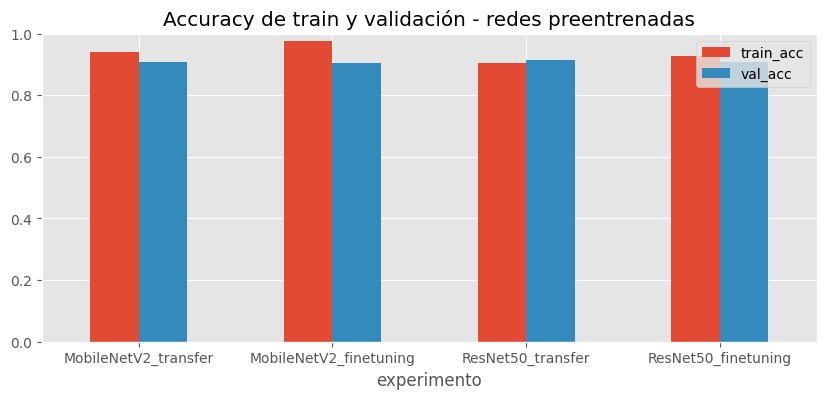

Mejor red preentrenada: ResNet50_transfer


In [ ]:
tabla_pre = pd.DataFrame(resultados)
tabla_pre = tabla_pre[tabla_pre["experimento"].str.contains("MobileNetV2|ResNet50")]
tabla_pre["diferencia (train - val)"] = (tabla_pre["train_acc"] - tabla_pre["val_acc"]).round(4)
print(tabla_pre)

tabla_pre.plot(x="experimento", y=["train_acc", "val_acc"], kind="bar", figsize=(10, 4))
plt.title("Accuracy de train y validación - redes preentrenadas")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

mejor_pre = tabla_pre.loc[tabla_pre["val_acc"].idxmax(), "experimento"]
print("Mejor red preentrenada:", mejor_pre)

<p align="justify" style="text-align: justify;"><b>Conclusión de la estrategia 2:</b> las cuatro configuraciones obtienen resultados <b>muy parecidos</b> en validación, con un <i>accuracy</i> de entre <b>0,905 y 0,913</b>.</p>

| Modelo | `val_acc` | `val_loss` | Diferencia train − val | Parámetros entrenados | Tiempo/época |
|---|---|---|---|---|---|
| MobileNetV2 *transfer* | 0,908 | 0,232 | 0,032 | ≈ 6.400 | ≈ 4 s |
| MobileNetV2 *fine-tuning* | 0,905 | 0,234 | 0,072 | ≈ 1,6 M | ≈ 4 s |
| **ResNet50 *transfer*** | **0,913** | 0,240 | **−0,007** | ≈ 10.200 | ≈ 8 s |
| ResNet50 *fine-tuning* | 0,909 | 0,226 | 0,019 | ≈ 15 M | ≈ 12 s |

<p align="justify" style="text-align: justify;">Observamos dos conclusiones claras:</p>

<ol style="text-align: justify;">
<li align="justify" style="text-align: justify;"><b>El <i>fine-tuning</i> no aporta mejora en ninguna de las dos redes</b> y aumenta el sobreajuste: la diferencia entre entrenamiento y validación pasa de 0,032 a 0,072 en MobileNetV2 y de −0,007 a 0,019 en ResNet50. Las características que las redes aprendieron en ImageNet ya son suficientes para distinguir nuestras cinco categorías, y 4.534 imágenes son pocas para reajustar millones de parámetros.</li>
<li align="justify" style="text-align: justify;"><b>La arquitectura más grande apenas mejora el resultado.</b> ResNet50 tiene unas 10 veces más parámetros que MobileNetV2 y tarda aproximadamente el doble por época, pero su <i>accuracy</i> de validación es solo 0,4 puntos mayor.</li>
</ol>

<p align="justify" style="text-align: justify;"><b>Elegimos ResNet50 con <i>transfer learning</i></b>, porque obtiene el <i>accuracy</i> de validación más alto (<b>0,913</b>) y es el único modelo <b>sin sobreajuste</b> en su mejor época: su <i>accuracy</i> de validación es incluso algo mayor que el de entrenamiento. Su principal inconveniente es el coste de cálculo. Si la velocidad fuera prioritaria (por ejemplo, para usar el modelo en un móvil), MobileNetV2 sería una alternativa casi equivalente.</p>

<p align="justify" style="text-align: justify;">Respecto a nuestra mejor CNN desde cero (E3, con un <i>accuracy</i> de validación de 0,81), la red preentrenada mejora unos <b>11 puntos</b>. La evaluación con el conjunto de test se realiza en el apartado 4.</p>


<a id="4"></a>
# 4. Evaluación y comparación de las estrategias

Comparamos el mejor modelo de cada estrategia:
- **Estrategia 1:** CNN desde cero **E3** (`GlobalAveragePooling2D` + *Dropout*).
- **Estrategia 2:** **ResNet50 con *transfer learning***.

Hasta ahora, todas las decisiones se han tomado con el conjunto de **validación**. En este apartado usamos por primera vez el conjunto de **test** (1.417 imágenes que ningún modelo ha visto ni ha influido en ninguna decisión), lo que nos da una medida honesta de la capacidad de generalización.


### 4.1. Rendimiento sobre el conjunto de test

[INFO]: Evaluando CNN desde cero (E3_gap) en test...
              precision    recall  f1-score   support

    drawings      0.681     0.626     0.653       246
   engraving      0.850     0.542     0.662       168
 iconography      0.828     0.952     0.886       460
    painting      0.824     0.744     0.782       164
   sculpture      0.835     0.897     0.865       379

    accuracy                          0.808      1417
   macro avg      0.804     0.752     0.769      1417
weighted avg      0.807     0.808     0.801      1417



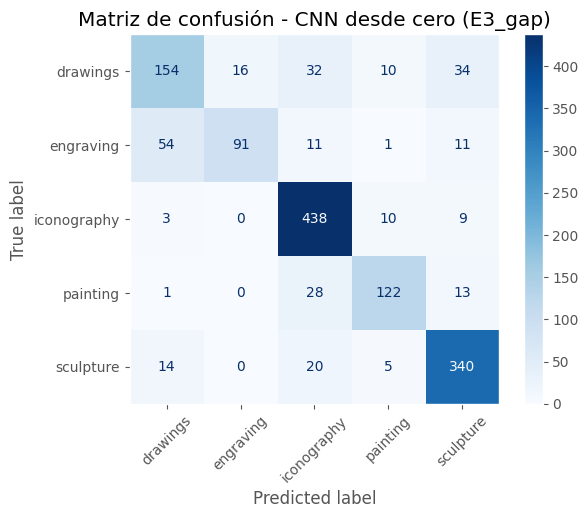

[INFO]: Evaluando ResNet50 transfer en test...
              precision    recall  f1-score   support

    drawings      0.746     0.825     0.784       246
   engraving      0.783     0.708     0.744       168
 iconography      0.970     0.985     0.977       460
    painting      0.907     0.829     0.866       164
   sculpture      0.992     0.984     0.988       379

    accuracy                          0.906      1417
   macro avg      0.880     0.866     0.872      1417
weighted avg      0.908     0.906     0.906      1417



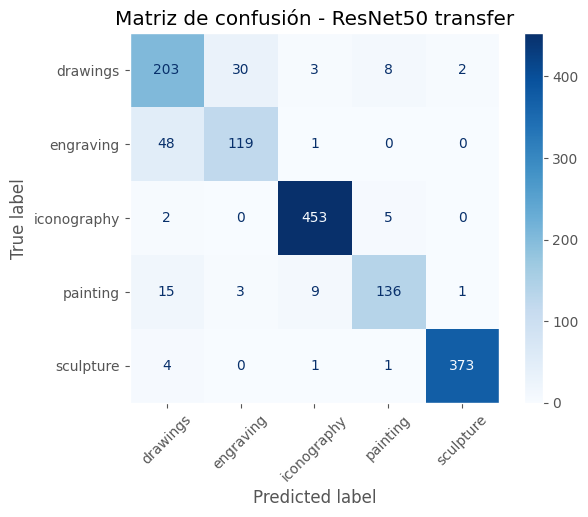

                    modelo  test_acc  test_f1_macro
0  CNN desde cero (E3_gap)    0.8080         0.7695
1        ResNet50 transfer    0.9061         0.8718


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score

# Recuperamos los pesos del transfer learning de ResNet50 (el modelo elegido en 3.4)
model_resnet.set_weights(pesos_resnet_transfer)

# Mejor modelo de cada estrategia: la CNN elegida en 2.7 y ResNet50 transfer
modelos_finales = {"CNN desde cero (" + mejor_nombre + ")": mejor_cnn,
                   "ResNet50 transfer": model_resnet}

resultados_test = []
predicciones = {}

for nombre, modelo in modelos_finales.items():
    print("[INFO]: Evaluando", nombre, "en test...")
    probabilidades = modelo.predict(x_te, batch_size=32, verbose=0)
    pred = probabilidades.argmax(axis=1)
    predicciones[nombre] = pred

    resultados_test.append({"modelo": nombre,
                            "test_acc": round(accuracy_score(y_te, pred), 4),
                            "test_f1_macro": round(f1_score(y_te, pred, average="macro"), 4)})

    # Informe por clase: precision, recall y F1
    print(classification_report(y_te, pred, target_names=clases, digits=3))

    # Matriz de confusión
    disp = ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=clases)
    disp.plot(cmap="Blues", xticks_rotation=45)
    disp.ax_.grid(False)
    plt.title("Matriz de confusión - " + nombre)
    plt.show()

tabla_test = pd.DataFrame(resultados_test)
print(tabla_test)

<p align="justify" style="text-align: justify;"><b>Análisis:</b> en el conjunto de test, <b>ResNet50 con <i>transfer learning</i> supera claramente a la CNN desde cero</b>: alcanza un <i>accuracy</i> de <b>0,906</b> frente a <b>0,808</b>, unos <b>10 puntos más</b>, y un F1 macro de <b>0,872</b> frente a <b>0,770</b>. El F1 macro (la media del F1 de las cinco clases, sin tener en cuenta cuántas imágenes tiene cada una) es especialmente importante en nuestro caso, porque las clases no están balanceadas.
</p>

<p align="justify" style="text-align: justify;"><b>Análisis por clase:</b>
</p>

| Clase | F1 CNN (E3) | F1 ResNet50 |
|---|---|---|
| drawings | 0,653 | 0,784 |
| engraving | 0,662 | 0,744 |
| iconography | 0,886 | 0,977 |
| painting | 0,782 | 0,866 |
| sculpture | 0,865 | 0,988 |

<ul style="text-align: justify;" align="justify">
<li align="justify">ResNet50 mejora <b>en todas las clases</b>. Las mayores mejoras están en <i>drawings</i> (+0,13) y <i>sculpture</i> (+0,12).</li>
<li align="justify"><b>La CNN desde cero tiene dificultades con <i>engraving</i> y <i>drawings</i></b>: su <i>recall</i> es de solo <b>0,54</b> y <b>0,63</b>, por lo que casi la mitad de los grabados y más de un tercio de los dibujos se clasifican como otra categoría.</li>
<li align="justify"><b>La CNN desde cero se inclina hacia <i>iconography</i></b>: reconoce casi todos los iconos (<i>recall</i> de 0,95), pero su <i>precision</i> es de 0,83, es decir, muchas obras que no son iconos se clasifican como tales. Es un efecto del <b>desbalance de clases</b>: <i>iconography</i> es la categoría con más imágenes, y el modelo "apuesta" por ella cuando duda. ResNet50 apenas sufre este problema (<i>precision</i> de 0,97).</li>
<li align="justify"><b>ResNet50 reconoce casi perfectamente <i>sculpture</i> (F1 de 0,99) e <i>iconography</i> (0,98)</b>, las categorías visualmente más diferentes: las esculturas son objetos tridimensionales y los iconos tienen un estilo muy característico, con fondos dorados.</li>
<li align="justify"><b>Para los dos modelos, las clases más difíciles son <i>drawings</i> y <i>engraving</i></b>. Son obras sobre papel, a menudo monocromas y con trazos lineales, por lo que incluso para una persona pueden resultar difíciles de distinguir.</li>
</ul>


<a id="5"></a>
# 5. Conclusiones

### 5.1. ¿Qué estrategia es mejor para nuestro problema?

**La estrategia basada en redes preentrenadas es la mejor solución para nuestro dataset.** ResNet50 con *transfer learning* alcanza un *accuracy* en test de **0,906** y un F1 macro de **0,872**, frente a **0,808** y **0,770** de nuestra mejor CNN desde cero (E3). Mejora en las cinco categorías, aprende en muy pocas épocas (su mejor resultado llega en la época 3, frente a la 29 de E3) y generaliza bien: su *accuracy* en test es prácticamente igual al de validación (0,906 frente a 0,913).

La razón principal es el **tamaño del dataset**. Con 4.534 imágenes de entrenamiento, una CNN desde cero tiene que aprender a la vez a detectar bordes, texturas y formas, y a combinarlas para distinguir los cinco tipos de obra. La red preentrenada **ya sabe detectar esas características**, porque las aprendió con más de un millón de imágenes de ImageNet, y solo necesita aprender a combinarlas. Aunque ImageNet contiene fotografías de objetos cotidianos y no obras de arte, estas características básicas también resultan útiles para nuestro problema.

Aun así, la CNN desde cero tiene ventajas: es unas **200 veces más ligera** que ResNet50 (unos 110.000 parámetros frente a unos 23,6 millones), por lo que es más rápida y podría usarse en dispositivos con pocos recursos, a cambio de unos **10 puntos** menos de *accuracy*.

### 5.2. Lo que hemos aprendido del proceso experimental

- **El sobreajuste de la red base se debía sobre todo al exceso de parámetros.** El *Dropout* lo retrasó, pero el cambio decisivo fue sustituir `Flatten` por `GlobalAveragePooling2D` (E3), que redujo los parámetros de 6,6 millones a 110.000 y eliminó el sobreajuste. Fue nuestro mejor modelo desde cero.
- **No todas las técnicas de regularización ayudan.** La *Batch Normalization* hizo la validación muy inestable y los resultados poco reproducibles, por lo que la descartamos. La regularización L2 dio un entrenamiento estable, pero **no mejoró a E3**, porque el modelo ya estaba suficientemente regularizado. El *data augmentation*, combinado con el resto de técnicas, provocó **subajuste**. La lección es que cada técnica debe responder a un problema observado, y que acumularlas puede llevar del sobreajuste al subajuste.
- **Las pequeñas diferencias entre experimentos deben interpretarse con cautela.** Al repetir los entrenamientos en GPU, un mismo modelo puede variar 1-2 puntos, por lo que E2, E3 y E5 tienen un rendimiento prácticamente equivalente.
- **En las redes preentrenadas, el *fine-tuning* no mejoró al *transfer learning*.** Al descongelar millones de parámetros con pocas imágenes, la red empezó a memorizar el entrenamiento: aumentó el sobreajuste sin mejorar la validación.
- **Una red más grande no siempre es mejor:** ResNet50 obtuvo prácticamente el mismo resultado que MobileNetV2, con unas 10 veces más parámetros y aproximadamente el doble de tiempo por época.
- **La limpieza de los datos fue fundamental.** Descubrimos que la carpeta `musemart` era casi una copia de `dataset` y que había 1.492 imágenes repetidas y 108 corruptas. Sin eliminarlas, el modelo se habría evaluado con imágenes que ya había visto y los resultados habrían parecido mejores de lo que son.

### 5.3. Respuesta a nuestra hipótesis y a nuestra pregunta de investigación

Partíamos de la hipótesis de que **los modelos preentrenados obtendrían mejores resultados**. **Los resultados la confirman**: ResNet50 supera a la CNN desde cero en unos **10 puntos** de *accuracy* en test.

Nuestra pregunta era **"¿nos engaña la CNN?"**, es decir, si la red reconoce realmente el tipo de obra o se deja llevar por detalles de la fotografía. Con nuestros resultados podemos afirmar que:

- Los dos modelos **generalizan bien a imágenes que no han visto**: la diferencia entre validación y test es menor de 1 punto (0,805 frente a 0,808 en E3, y 0,913 frente a 0,906 en ResNet50).
- Los errores se concentran en las categorías **más parecidas visualmente** (*drawings* y *engraving*, obras sobre papel, a menudo monocromas y con trazos lineales), lo que indica que los modelos se basan, al menos en parte, en características propias de las obras.

Sin embargo, **no podemos responder completamente a la segunda parte de la hipótesis**, la de que la precisión disminuiría con imágenes de otra colección. Nuestro plan era usar `musemart` como colección independiente, pero comprobamos que el **96,76 %** de sus imágenes ya estaba en `dataset`. Como las imágenes de entrenamiento y de test proceden de las mismas fuentes, no podemos descartar que los modelos aprovechen características comunes de esas fotografías.

### 5.4. Limitaciones y trabajo futuro

- **Evaluar con una colección realmente independiente** (por ejemplo, imágenes de otro museo), para comprobar si los modelos mantienen su rendimiento con otro tipo de fotografías.
- **Visualizar las zonas de la imagen en las que se fija la red** (por ejemplo, con Grad-CAM), para comprobar si el modelo mira la obra o el fondo.
- **Mejorar la CNN desde cero:** entrenar E3 durante más épocas (seguía mejorando al llegar a la 30) y combinar el *data augmentation* con menos *Dropout* para evitar el subajuste.
- **Tratar el desbalance de clases** (por ejemplo, con `class_weight`), ya que la CNN desde cero tiende a clasificar como *iconography*, la clase más numerosa, las obras sobre las que duda.
- **Repetir los entrenamientos varias veces** para medir la variabilidad de los resultados, ya que un mismo modelo puede dar resultados algo diferentes en distintas ejecuciones, sobre todo con *Batch Normalization*.



<div style="font-family:Arial,sans-serif;font-size:14px;line-height:1.6;text-align:justify;">
<h2>6. Bibliografía y recursos utilizados</h2>
<p>Para preparar este trabajo hemos utilizado el enunciado y los notebooks de la asignatura, la documentación oficial de TensorFlow/Keras, el dataset de Kaggle y herramientas de Python. También hemos utilizado ChatGPT como apoyo para revisar y completar el código, organizar los experimentos y mejorar la redacción. Las decisiones metodológicas y los resultados deberán comprobarse mediante la ejecución del notebook.</p>
</div>

<div style="font-family:Arial,sans-serif;font-size:14px;line-height:1.6;text-align:justify;">

<ul>
<li>VIU. <i>07MIAR – Redes Neuronales y Deep Learning: Proyecto de programación «Deep Vision in classification tasks»</i>. Material docente de la asignatura.</li>
<li>VIU. <i>07MIAR_SP02_Deep_Vision</i> y <i>07MIAR_VC04_VC05_DeepVision_Jupyter</i>. Notebooks de clase.</li>
<li>thedownhill. <i>Art Images (Drawings, Painting, Sculpture, Engraving)</i>. Kaggle. https://www.kaggle.com/datasets/thedownhill/art-images-drawings-painting-sculpture-engraving</li>
<li>TensorFlow/Keras. <i>Keras Applications</i>. https://keras.io/api/applications/</li>
<li>TensorFlow/Keras. <i>Guías de transfer learning y fine-tuning</i>. https://keras.io/guides/transfer_learning/</li>
<li>Scikit-learn. <i>Documentación de métricas de clasificación</i>. https://scikit-learn.org/stable/modules/model_evaluation.html</li>
<li>OpenAI. ChatGPT, apoyo en revisión de código, generación de gráficas y redacción; resultados sujetos a comprobación en Colab.</li>
</ul>
</div>

In [ ]:
# Comprobación final antes de exportar
nombres = [r["experimento"] for r in resultados]
esperados = ["E1_base", "E2_dropout", "E3_gap", "E4_batchnorm", "E5_l2", "E6_augmentation",
             "MobileNetV2_transfer", "MobileNetV2_finetuning", "ResNet50_transfer", "ResNet50_finetuning"]

assert len(clases) == 5, "Comprobar categorías del dataset"
assert len(nombres) == len(set(nombres)), "Hay experimentos repetidos en la tabla"
assert sorted(nombres) == sorted(esperados), "Faltan experimentos por ejecutar o hay alguno de más"
assert len(resultados_test) == 2, "Faltan evaluaciones en test"

print("✅ Experimentos registrados:", len(resultados))
print("✅ Modelos evaluados en test:", len(resultados_test))
print("✅ Tablas y gráficas generadas por las celdas anteriores")
print("Guarda el .ipynb ejecutado y expórtalo a PDF.")

✅ Experimentos registrados: 10
✅ Modelos evaluados en test: 2
✅ Tablas y gráficas generadas por las celdas anteriores
Guarda el .ipynb ejecutado y expórtalo a PDF.


---
## Anexo: generación del PDF

Ejecutar al final, con todo el notebook ya ejecutado y guardado.

In [1]:
# Generación del PDF a partir del notebook (.ipynb) guardado en Google Drive
from google.colab import drive
#drive.mount("/content/drive")

NOTEBOOK = "/content/Grupo17_Ortiz Sabogal_Cesar Jose.ipynb"

!pip install -q "nbconvert[webpdf]"
!playwright install --with-deps chromium > /dev/null
!jupyter nbconvert --to webpdf "{NOTEBOOK}" --output-dir "/content"

from google.colab import files
files.download("/content/Grupo17_Ortiz Sabogal_Cesar Jose.pdf")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[NbConvertApp] Converting notebook /content/Grupo17_Ortiz Sabogal_Cesar Jose.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 18 image(s).
[NbConvertApp] Building PDF
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 4249723 bytes to /content/Grupo17_Ortiz Sabogal_Cesar Jose.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>